# Avaliação de cenários

Os resultados seguem a ordem do roteiro, com tabelas completas de cenários e seções para cada conjunto de dados: mapas de velocidade, métricas de qualidade, médias por fator e custos medidos na avaliação.

O percentual de cenários em que cada modelo alcança o melhor resultado aparece em uma seção separada, após as tabelas detalhadas.

As métricas de qualidade são MSE, MAE e SSIM. Cada tabela e gráfico mantém os resultados dentro do próprio conjunto de dados.

Nos gráficos de latência, cada barra é a média das medianas medidas por execução, e as barras de erro mostram o desvio padrão entre execuções. O CSV também registra média, desvio padrão e p90 das repetições cronometradas de cada execução.

## Roteiro de execução

1. Configurar versão, dispositivo e protocolo de medição.
2. Avaliar os checkpoints e salvar os resultados.
3. Consultar as tabelas completas de cenários.
4. Comparar os modelos pelos resultados.
5. Inspecionar os mapas de velocidade.
6. Consultar métricas por cenário.
7. Consultar médias por ruído, geometria e modelo.
8. Comparar latência e memória, incluindo os modelos Mamba com blocos ativos e inativos.
9. Comparar a propagação usando velocidade de referência e U-Net Mamba.


In [1]:
import json
import pandas as pd
from pathlib import Path

from IPython.display import Image, Markdown, display

from config.config import DEFAULT_CHECKPOINT_ROOT, EVALUATION_ROOT, resolve_device
from network.evaluation import (
    evaluate_scenario_dataset,
    write_scenario_grouped_presentation_tables,
    write_scenario_runtime_presentation_table,
)
from helpers.mamba_memory import benchmark_mamba_memory_variants
from run_training import DATASET_RECEIVER_GEOMETRIES
from visualization.charts.metrics import plot_grouped_scenario_metric_charts
from visualization.charts.performance import plot_scenario_runtime_charts
from visualization.evaluation_tables import (
    display_scenario_tables,
    display_scenario_comparative_analysis,
)
from visualization.evaluation_wavefield import display_unetmamba_wavefield_comparison


## 1. Configuração da avaliação

A versão, o dispositivo, o protocolo de medição e os caminhos dos artefatos são definidos a partir da configuração da avaliação.


In [2]:
PRESENTATION_CONFIG_PATH = Path("config/evaluation_presentation.json")
PRESENTATION_CONFIG = json.loads(PRESENTATION_CONFIG_PATH.read_text(encoding="utf-8"))
DATASET_NAMES = tuple(item["name"] for item in PRESENTATION_CONFIG["datasets"])
DEVICE = resolve_device("cuda_if_available")
PERFORMANCE_BENCHMARK = PRESENTATION_CONFIG.get("performance_benchmark", {})
REUSE_COMPLETED_EVALUATIONS = True


def scenario_output_dir(dataset_name):
    dataset = next(item for item in PRESENTATION_CONFIG["datasets"] if item["name"] == dataset_name)
    directory_name = dataset.get(
        "output_dir",
        PRESENTATION_CONFIG["scenario_output_dir"].format(dataset=dataset_name),
    )
    return EVALUATION_ROOT / PRESENTATION_CONFIG["version"] / directory_name


def scenario_factor_table_path(dataset_name):
    dataset = next(item for item in PRESENTATION_CONFIG["datasets"] if item["name"] == dataset_name)
    filename_template = dataset.get(
        "factor_table_filename",
        PRESENTATION_CONFIG["factor_table_filename"],
    )
    filename = filename_template.format(
        dataset=dataset_name,
        version=PRESENTATION_CONFIG["version"],
    )
    return scenario_output_dir(dataset_name) / filename


def scenario_presentation_table_path(dataset_name):
    filename = PRESENTATION_CONFIG["presentation_table_filename"].format(
        dataset=dataset_name,
        version=PRESENTATION_CONFIG["version"],
    )
    return scenario_output_dir(dataset_name) / filename



print("Versão:", PRESENTATION_CONFIG["version"])
print("Dispositivo:", DEVICE)
print("Aquecimento e repetições:", PERFORMANCE_BENCHMARK)
print("Conjuntos de dados:", ", ".join(DATASET_NAMES))


Versão: v8
Dispositivo: cuda
Aquecimento e repetições: {'warmup_runs': 5, 'timed_runs': 30}
Conjuntos de dados: Marmousi, FlatFault_A, CurveVel_A, CurveFault_B


## 2. Avaliação dos checkpoints

Altere o campo `version` em `config/evaluation_presentation.json` para a versão dos checkpoints disponíveis e execute as células seguintes. O avaliador reutiliza resultados completos compatíveis quando eles existem; caso contrário, avalia os checkpoints dessa versão e salva os artefatos na pasta correspondente.


In [3]:
scenario_results = {}

for dataset_name in DATASET_NAMES:
    result = evaluate_scenario_dataset(
        dataset_name,
        version=PRESENTATION_CONFIG["version"],
        checkpoint_root=DEFAULT_CHECKPOINT_ROOT,
        output_dir=scenario_output_dir(dataset_name),
        factor_table_path=scenario_factor_table_path(dataset_name),
        presentation_table_path=scenario_presentation_table_path(dataset_name),
        metric_definitions=PRESENTATION_CONFIG["metrics"],
        performance_definitions=PRESENTATION_CONFIG["performance_metrics"],
        device=DEVICE,
        performance_benchmark=PERFORMANCE_BENCHMARK,
        reuse_completed=REUSE_COMPLETED_EVALUATIONS,
    )
    scenario_results[dataset_name] = result
    successful = sum(row.get("status") == "ok" for row in result.output.manifest)
    failed = sum(row.get("status") != "ok" for row in result.output.manifest)
    print(
        f"{dataset_name}: {successful} avaliações concluídas, "
        f"{failed} falhas, {len(result.factor_table)} cenários"
    )
    print("  resultados:", result.output.job.output_dir)
    for row in result.output.manifest:
        if row.get("status") != "ok":
            print("  ", row.get("run_name", row.get("model_name")), row.get("status"), row.get("message"))


Marmousi: 40 avaliações concluídas, 0 falhas, 20 cenários
  resultados: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/Marmousi_model_scenarios
FlatFault_A: 40 avaliações concluídas, 0 falhas, 20 cenários
  resultados: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/FlatFault_A_model_scenarios
CurveVel_A: 40 avaliações concluídas, 0 falhas, 20 cenários
  resultados: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/CurveVel_A_model_scenarios
CurveFault_B: 40 avaliações concluídas, 0 falhas, 20 cenários
  resultados: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/CurveFault_B_model_scenarios


## 3. Tabelas completas de cenários

O notebook mostra uma tabela completa por conjunto de dados, com as combinações de ruído, épocas e geometrias daquele conjunto de dados. Todos os modelos ficam na tabela; cenários sem avaliação permanecem com métricas vazias. Épocas separam cenários internamente e não aparecem como coluna. As setas indicam a direção de melhor resultado para MSE, MAE e SSIM.


In [4]:
display_scenario_tables(
    scenario_results=scenario_results,
    dataset_names=DATASET_NAMES,
    presentation_config=PRESENTATION_CONFIG,
    receiver_geometries=DATASET_RECEIVER_GEOMETRIES,
)


### Marmousi

Média ± desvio padrão entre amostras. O melhor resultado entre os modelos em cada cenário está em negrito. Linhas duplas separam cenários; células vazias indicam cenários sem avaliações concluídas.

Conjunto de dados,Modelo,Ruído,Geometria,MSE ↓,MAE ↓,SSIM ↑
Marmousi,PGNN (Mardan 2024),Sem ruído,superfície,"150269,52 ± 5087,62","211,00 ± 4,18","0,619 ± 0,000"
Marmousi,PGANN (Mardan 2024),Sem ruído,superfície,"149052,23 ± 34387,55","216,88 ± 36,73","0,623 ± 0,033"
Marmousi,U-Net,Sem ruído,superfície,"42124,23 ± 3956,35","106,07 ± 3,19","0,771 ± 0,005"
Marmousi,Mamba,Sem ruído,superfície,"77115,21 ± 4712,54","145,57 ± 5,75","0,729 ± 0,010"
Marmousi,U-Net Mamba,Sem ruído,superfície,"49810,44 ± 2066,37","108,20 ± 3,76","0,786 ± 0,003"
Marmousi,PGNN (Mardan 2024),Sem ruído,superfície + poços,"33958,34 ± 360,24","102,11 ± 0,77","0,728 ± 0,000"
Marmousi,PGANN (Mardan 2024),Sem ruído,superfície + poços,"20359,46 ± 38,48","77,12 ± 0,35","0,802 ± 0,003"
Marmousi,U-Net,Sem ruído,superfície + poços,"16683,88 ± 188,11","70,33 ± 0,31","0,819 ± 0,003"
Marmousi,Mamba,Sem ruído,superfície + poços,"16776,29 ± 397,63","69,54 ± 1,22","0,830 ± 0,002"
Marmousi,U-Net Mamba,Sem ruído,superfície + poços,"14879,78 ± 188,44","63,83 ± 0,34","0,850 ± 0,001"


### FlatFault_A

Média ± desvio padrão entre amostras. O melhor resultado entre os modelos em cada cenário está em negrito. Linhas duplas separam cenários; células vazias indicam cenários sem avaliações concluídas.

Conjunto de dados,Modelo,Ruído,Geometria,MSE ↓,MAE ↓,SSIM ↑
FlatFault_A,PGNN (Mardan 2024),Sem ruído,superfície,"331114,67 ± 46737,89","378,59 ± 6,30","0,438 ± 0,042"
FlatFault_A,PGANN (Mardan 2024),Sem ruído,superfície,"10900,80 ± 5599,05","56,84 ± 20,22","0,866 ± 0,035"
FlatFault_A,U-Net,Sem ruído,superfície,"9117,38 ± 918,17","72,98 ± 3,95","0,681 ± 0,011"
FlatFault_A,Mamba,Sem ruído,superfície,"3584,93 ± 1755,29","35,25 ± 8,84","0,913 ± 0,006"
FlatFault_A,U-Net Mamba,Sem ruído,superfície,"2674,90 ± 1442,55","29,87 ± 7,85","0,943 ± 0,012"
FlatFault_A,PGNN (Mardan 2024),Sem ruído,superfície + poços,"2133,03 ± 1447,90","22,56 ± 10,57","0,786 ± 0,081"
FlatFault_A,PGANN (Mardan 2024),Sem ruído,superfície + poços,"1714,75 ± 1191,68","13,32 ± 6,17","0,962 ± 0,015"
FlatFault_A,U-Net,Sem ruído,superfície + poços,"2114,02 ± 1079,32","24,00 ± 5,16","0,779 ± 0,017"
FlatFault_A,Mamba,Sem ruído,superfície + poços,"1293,75 ± 651,65","12,97 ± 3,06","0,972 ± 0,003"
FlatFault_A,U-Net Mamba,Sem ruído,superfície + poços,"669,19 ± 326,29","9,54 ± 2,42","0,981 ± 0,003"


### CurveVel_A

Média ± desvio padrão entre amostras. O melhor resultado entre os modelos em cada cenário está em negrito. Linhas duplas separam cenários; células vazias indicam cenários sem avaliações concluídas.

Conjunto de dados,Modelo,Ruído,Geometria,MSE ↓,MAE ↓,SSIM ↑
CurveVel_A,PGNN (Mardan 2024),Sem ruído,superfície,"297047,07 ± 118999,52","369,86 ± 95,16","0,427 ± 0,155"
CurveVel_A,PGANN (Mardan 2024),Sem ruído,superfície,"150540,65 ± 97598,21","250,81 ± 96,95","0,624 ± 0,037"
CurveVel_A,U-Net,Sem ruído,superfície,"180037,50 ± 80853,61","287,37 ± 86,99","0,504 ± 0,107"
CurveVel_A,Mamba,Sem ruído,superfície,"53335,79 ± 27895,03","146,04 ± 40,13","0,733 ± 0,013"
CurveVel_A,U-Net Mamba,Sem ruído,superfície,"60470,29 ± 36736,24","152,66 ± 52,64","0,736 ± 0,028"
CurveVel_A,PGNN (Mardan 2024),Sem ruído,superfície + poços,"15972,86 ± 1001,33","71,80 ± 2,08","0,714 ± 0,046"
CurveVel_A,PGANN (Mardan 2024),Sem ruído,superfície + poços,"11829,04 ± 648,28","52,02 ± 0,99","0,854 ± 0,022"
CurveVel_A,U-Net,Sem ruído,superfície + poços,"11460,82 ± 265,72","56,43 ± 4,84","0,804 ± 0,072"
CurveVel_A,Mamba,Sem ruído,superfície + poços,"7550,92 ± 2,70","40,52 ± 1,94","0,885 ± 0,014"
CurveVel_A,U-Net Mamba,Sem ruído,superfície + poços,"7730,30 ± 1308,99","38,50 ± 3,25","0,900 ± 0,012"


### CurveFault_B

Média ± desvio padrão entre amostras. O melhor resultado entre os modelos em cada cenário está em negrito. Linhas duplas separam cenários; células vazias indicam cenários sem avaliações concluídas.

Conjunto de dados,Modelo,Ruído,Geometria,MSE ↓,MAE ↓,SSIM ↑
CurveFault_B,PGNN (Mardan 2024),Sem ruído,superfície,"639639,78 ± 73864,59","569,54 ± 32,79","0,376 ± 0,001"
CurveFault_B,PGANN (Mardan 2024),Sem ruído,superfície,"213980,84 ± 66261,07","318,94 ± 64,06","0,525 ± 0,071"
CurveFault_B,U-Net,Sem ruído,superfície,"281407,98 ± 88879,55","377,58 ± 61,77","0,486 ± 0,069"
CurveFault_B,Mamba,Sem ruído,superfície,"250646,05 ± 40505,02","335,12 ± 22,96","0,585 ± 0,022"
CurveFault_B,U-Net Mamba,Sem ruído,superfície,"239230,14 ± 152091,49","311,53 ± 124,47","0,631 ± 0,112"
CurveFault_B,PGNN (Mardan 2024),Sem ruído,superfície + poços,"32886,21 ± 2412,00","114,75 ± 1,15","0,655 ± 0,008"
CurveFault_B,PGANN (Mardan 2024),Sem ruído,superfície + poços,"23401,50 ± 2718,89","88,33 ± 4,44","0,782 ± 0,013"
CurveFault_B,U-Net,Sem ruído,superfície + poços,"25071,15 ± 1983,55","90,59 ± 1,03","0,767 ± 0,002"
CurveFault_B,Mamba,Sem ruído,superfície + poços,"19318,05 ± 2151,56","75,84 ± 3,24","0,829 ± 0,015"
CurveFault_B,U-Net Mamba,Sem ruído,superfície + poços,"17226,48 ± 1042,45","69,66 ± 0,89","0,845 ± 0,014"


## 4. Análise comparativa dos modelos

A tabela detalhada acima tem 20 registros por base (cinco modelos em quatro condições comparáveis). Nas tabelas de percentual por modelo, `n` conta comparações amostra-cenário: oito por base, correspondentes às duas amostras em cada combinação de ruído e geometria. A tabela Total reúne até 32 comparações válidas. MSE e MAE são minimizados; SSIM é maximizado. Empates dividem igualmente o crédito, e só entram comparações válidas para todos os modelos. Na tabela comparativa final, cada coluna reúne um nível de ruído e uma geometria, com até oito comparações entre as quatro bases e as duas amostras. Os percentuais são descritivos.


In [5]:
display_scenario_comparative_analysis(
    scenario_results=scenario_results,
    dataset_names=DATASET_NAMES,
    presentation_config=PRESENTATION_CONFIG,
)


### Marmousi

Modelo,MSE ↓ (n=8),MAE ↓ (n=8),SSIM ↑ (n=8)
PGNN (Mardan 2024) | sem ruído | 500 épocas | superfície,"0,0%","0,0%","0,0%"
PGANN (Mardan 2024) | sem ruído | 500 épocas | superfície,"0,0%","0,0%","0,0%"
U-Net | sem ruído | 500 épocas | superfície,"50,0%","25,0%","0,0%"
Mamba | sem ruído | 500 épocas | superfície,"25,0%","25,0%","37,5%"
U-Net Mamba | sem ruído | 500 épocas | superfície,"25,0%","50,0%","62,5%"


### FlatFault_A

Modelo,MSE ↓ (n=8),MAE ↓ (n=8),SSIM ↑ (n=8)
PGNN (Mardan 2024) | sem ruído | 500 épocas | superfície,"0,0%","0,0%","0,0%"
PGANN (Mardan 2024) | sem ruído | 500 épocas | superfície,"25,0%","37,5%","12,5%"
U-Net | sem ruído | 500 épocas | superfície,"0,0%","0,0%","0,0%"
Mamba | sem ruído | 500 épocas | superfície,"0,0%","12,5%","25,0%"
U-Net Mamba | sem ruído | 500 épocas | superfície,"75,0%","50,0%","62,5%"


### CurveVel_A

...

### Total — todos os conjuntos de dados e amostras

Modelo,MSE ↓ (n=32),MAE ↓ (n=32),SSIM ↑ (n=32)
PGNN (Mardan 2024) | sem ruído | 500 épocas | superfície,"0,0%","0,0%","0,0%"
PGANN (Mardan 2024) | sem ruído | 500 épocas | superfície,"15,6%","15,6%","9,4%"
U-Net | sem ruído | 500 épocas | superfície,"15,6%","9,4%","0,0%"
Mamba | sem ruído | 500 épocas | superfície,"25,0%","21,9%","37,5%"
U-Net Mamba | sem ruído | 500 épocas | superfície,"43,8%","53,1%","53,1%"


### Análise comparativa por cenário e métrica — todos os conjuntos de dados

Cada coluna reúne um nível de ruído e uma geometria. Cada comparação válida corresponde a uma amostra do mesmo conjunto de dados e época; cada célula mostra percentuais de vitória para MSE, MAE e SSIM, nessa ordem e separados por ponto e vírgula. Empates dividem o crédito.

Modelo,Sem ruído | superfície,Sem ruído | superfície + poços,"Ruído 0,5 | superfície","Ruído 0,5 | superfície + poços"
PGNN (Mardan 2024) | sem ruído | 500 épocas | superfície,"(0,0%; 0,0%; 0,0%)","(0,0%; 0,0%; 0,0%)","(0,0%; 0,0%; 0,0%)","(0,0%; 0,0%; 0,0%)"
PGANN (Mardan 2024) | sem ruído | 500 épocas | superfície,"(12,5%; 12,5%; 0,0%)","(0,0%; 0,0%; 0,0%)","(37,5%; 37,5%; 37,5%)","(12,5%; 12,5%; 0,0%)"
U-Net | sem ruído | 500 épocas | superfície,"(25,0%; 25,0%; 0,0%)","(0,0%; 0,0%; 0,0%)","(37,5%; 12,5%; 0,0%)","(0,0%; 0,0%; 0,0%)"
Mamba | sem ruído | 500 épocas | superfície,"(12,5%; 25,0%; 25,0%)","(12,5%; 0,0%; 0,0%)","(12,5%; 37,5%; 50,0%)","(62,5%; 25,0%; 75,0%)"
U-Net Mamba | sem ruído | 500 épocas | superfície,"(50,0%; 37,5%; 75,0%)","(87,5%; 100,0%; 100,0%)","(12,5%; 12,5%; 12,5%)","(25,0%; 62,5%; 25,0%)"


## 5. Mapas de velocidade

Cada figura compara a velocidade de referência com as predições disponíveis para uma amostra do conjunto de dados. Os modelos e cenários aparecem juntos na figura para facilitar a comparação visual.


### Marmousi

Cenários de velocidade do modelo Marmousi.

#### Amostra 0

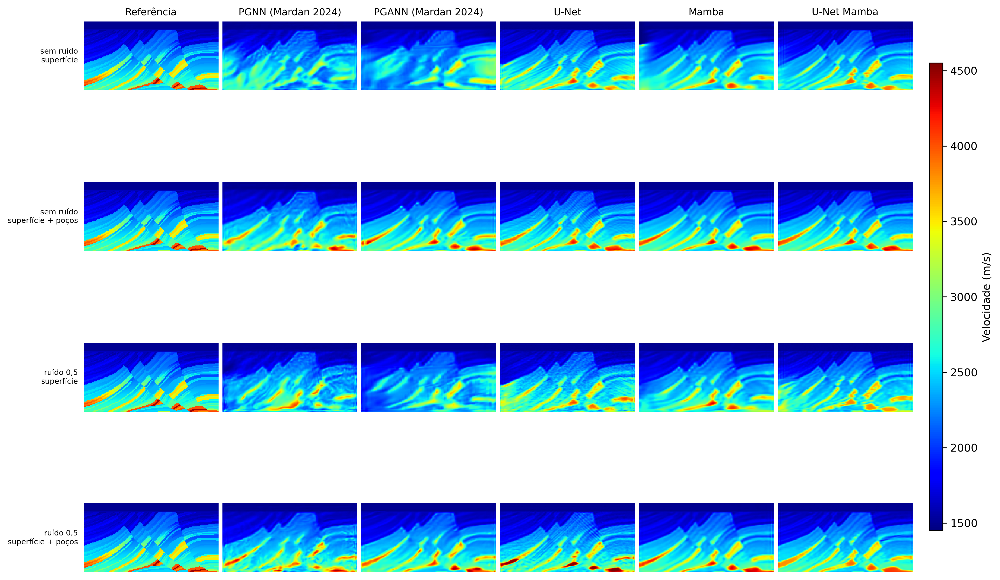

#### Amostra 1

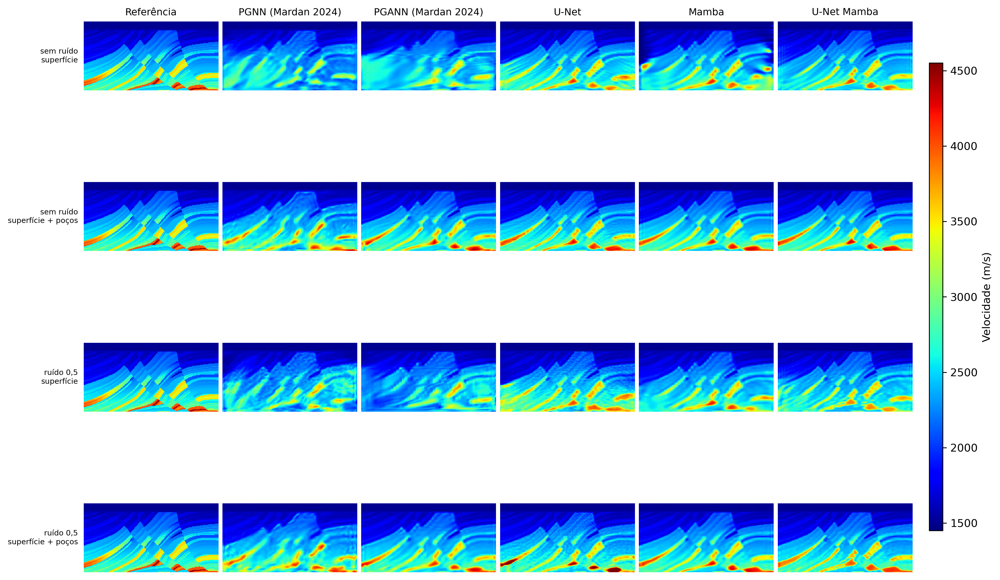

### FlatFault_A

Cenários de velocidade para falhas planas.

#### Amostra 0

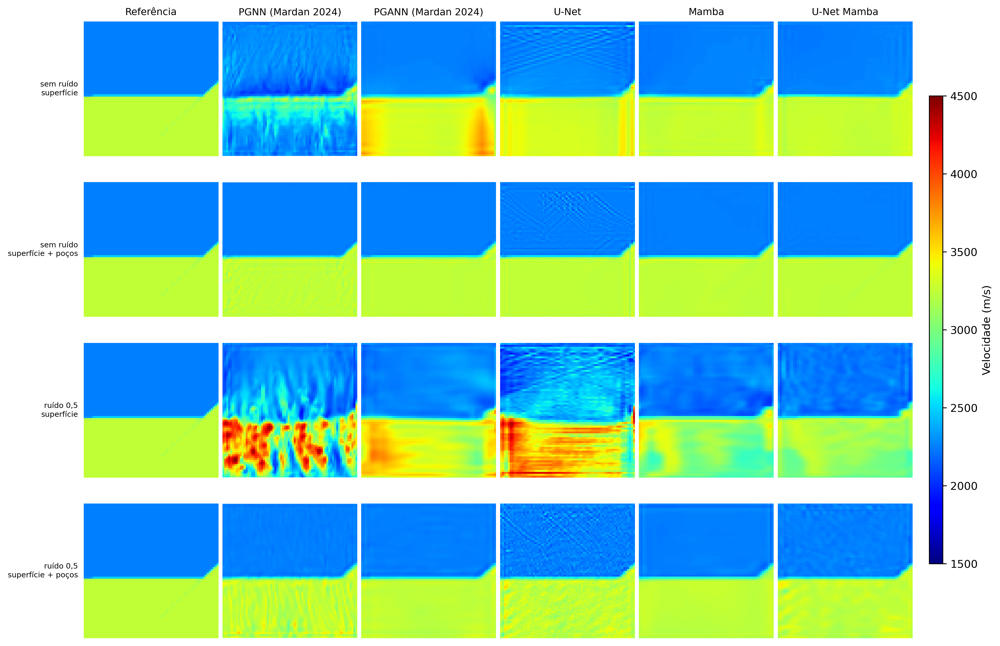

#### Amostra 1

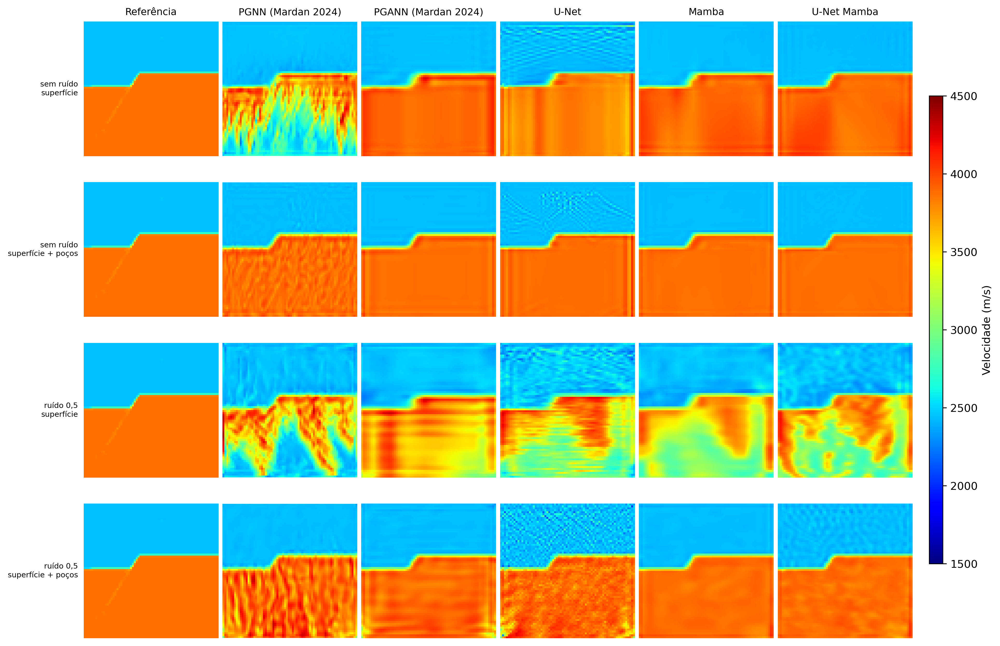

### CurveVel_A

Cenários de velocidade com estruturas curvas.

#### Amostra 0

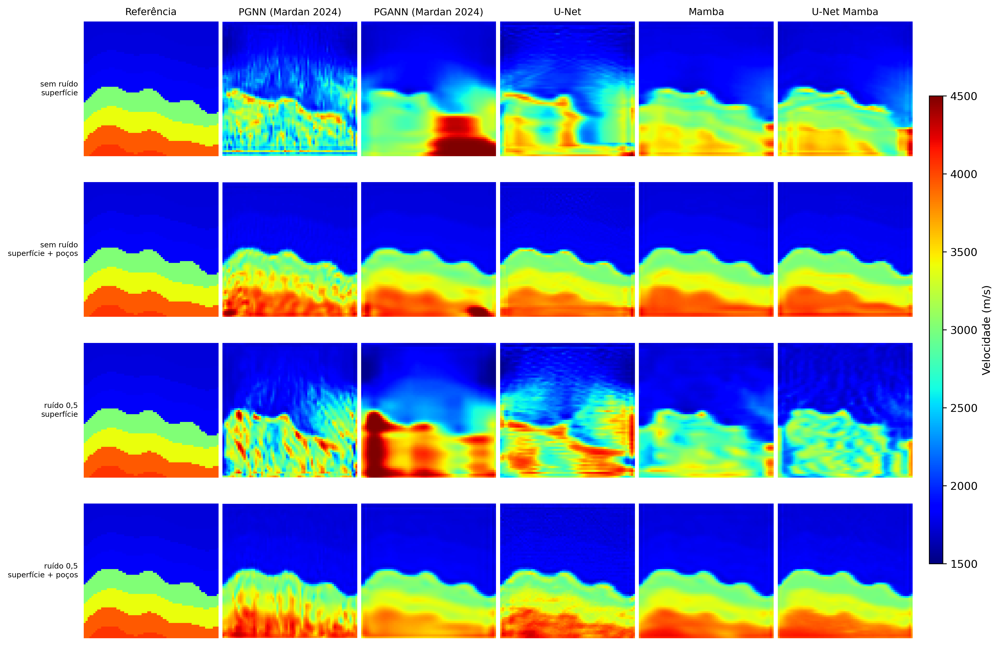

#### Amostra 1

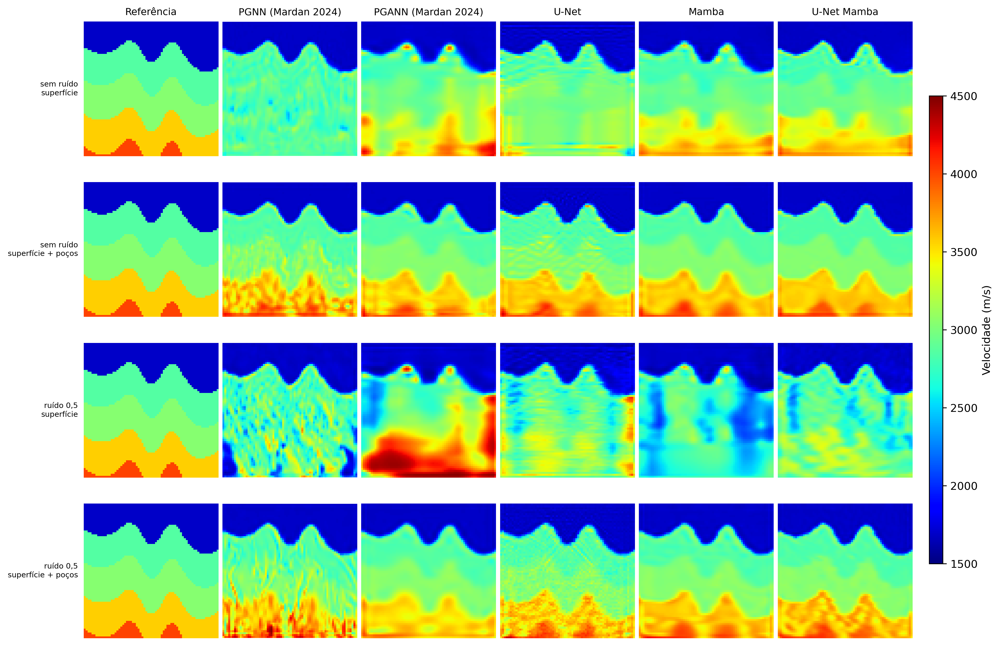

### CurveFault_B

Cenários de velocidade com falhas curvas.

#### Amostra 0

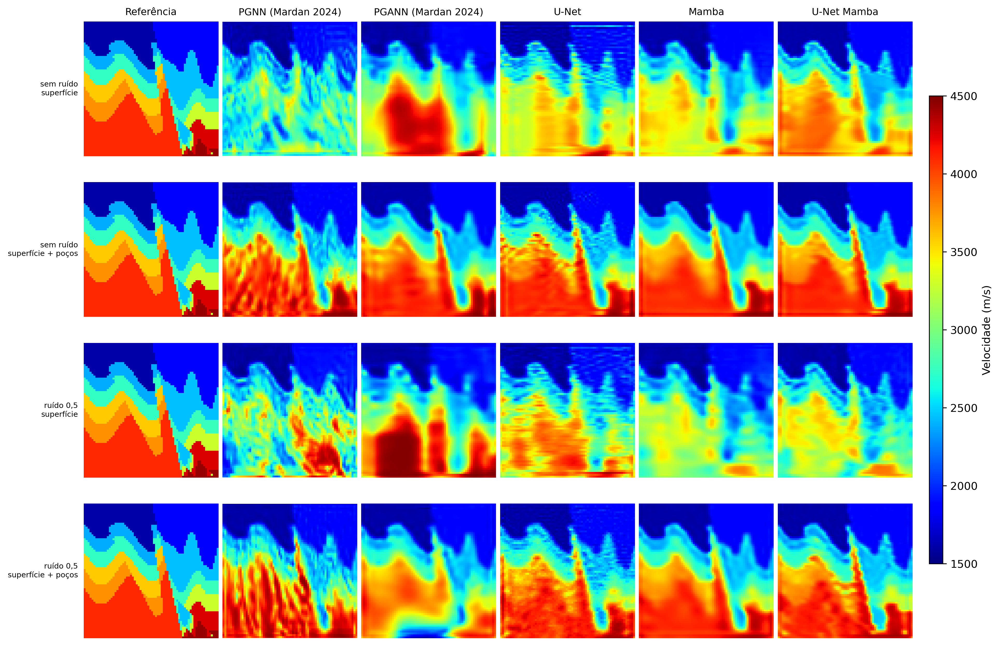

#### Amostra 1

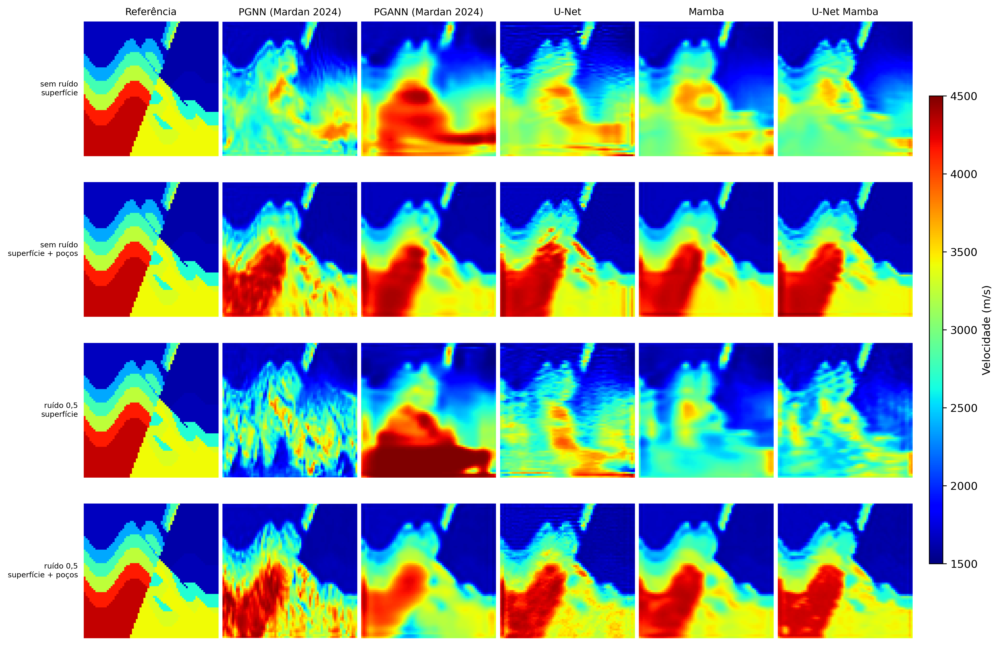

In [6]:
for dataset in PRESENTATION_CONFIG["datasets"]:
    dataset_name = dataset["name"]
    display(Markdown(f"### {dataset_name}\n\n{dataset['description']}"))
    figures = sorted(scenario_results[dataset_name].map_figures)
    if not figures:
        display(Markdown("Nenhum mapa foi gerado para este conjunto de dados. Consulte o manifesto da avaliação."))
    for figure_path in figures:
        sample_id = int(Path(figure_path).stem.rsplit("_s", 1)[1].split("_", 1)[0])
        display(Markdown(f"#### Amostra {sample_id}"))
        display(Image(filename=str(figure_path)))


## 6. Métricas por conjunto de dados e cenário

Cada conjunto de dados tem figuras próprias. O eixo horizontal agrupa seus fatores de treinamento; as séries mantêm um modelo por cor. As barras mostram médias entre amostras avaliadas. MSE e MAE diminuem quando a predição melhora; SSIM aumenta.


### Marmousi

Cenários de velocidade do modelo Marmousi.

#### MSE

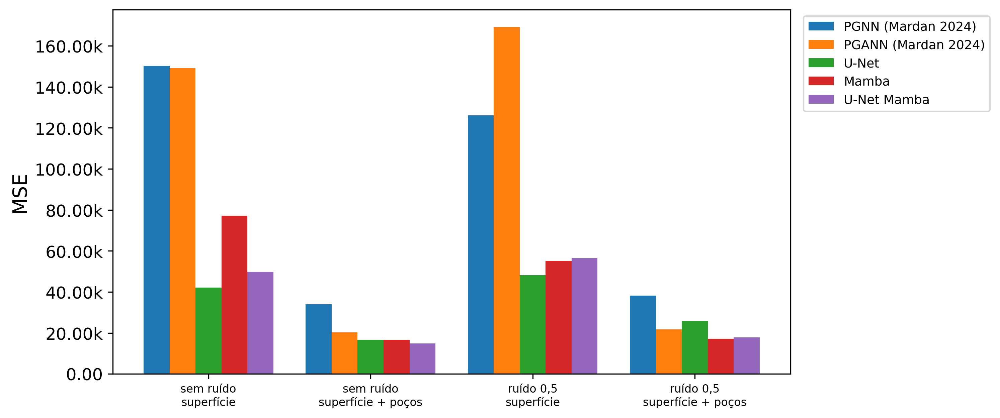

#### MAE

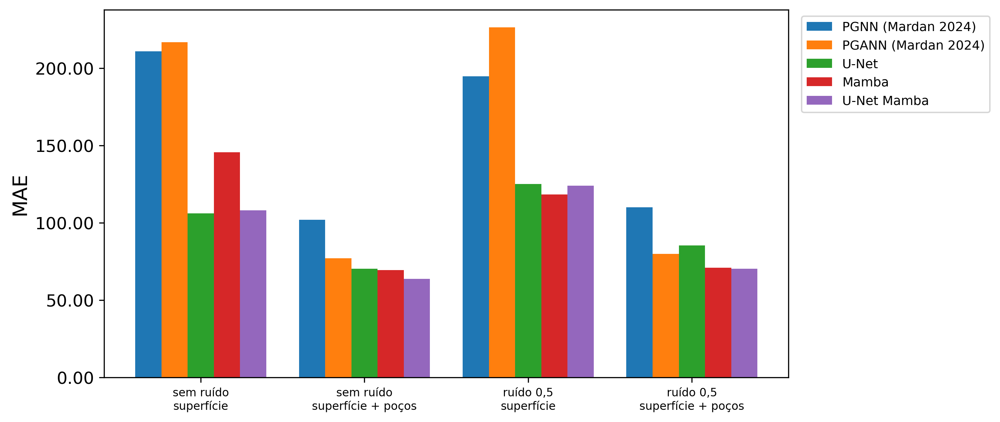

#### SSIM

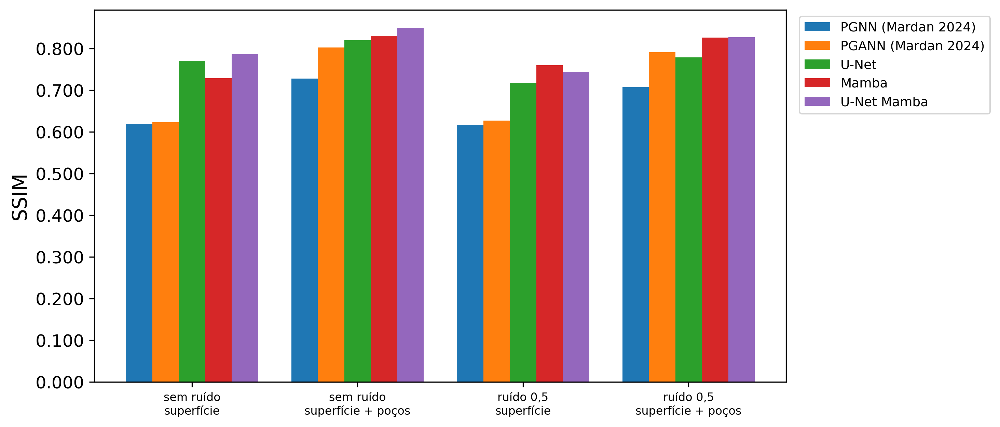

### FlatFault_A

Cenários de velocidade para falhas planas.

#### MSE

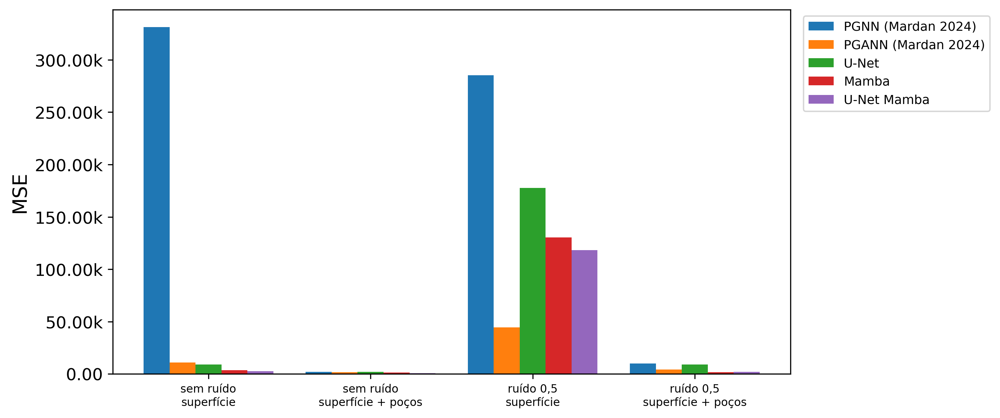

#### MAE

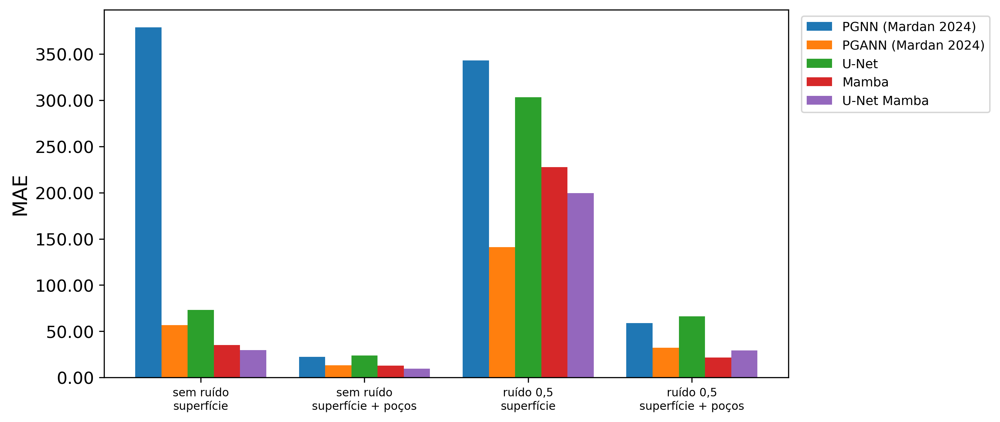

#### SSIM

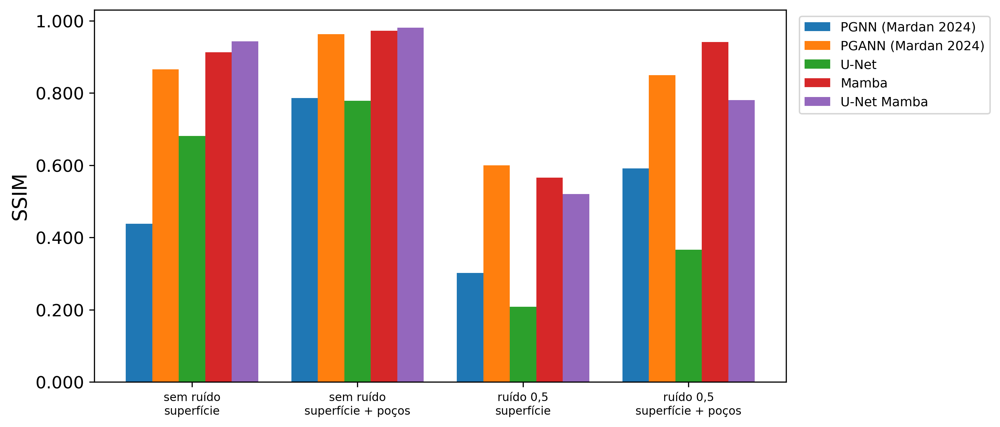

### CurveVel_A

Cenários de velocidade com estruturas curvas.

#### MSE

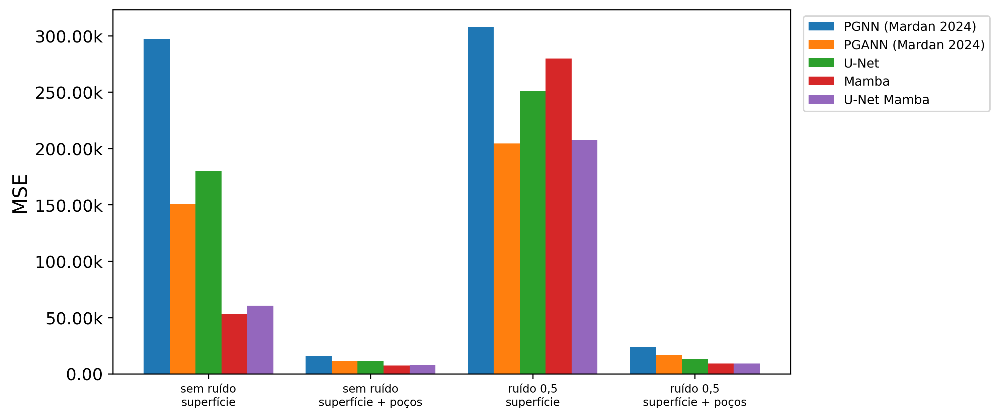

#### MAE

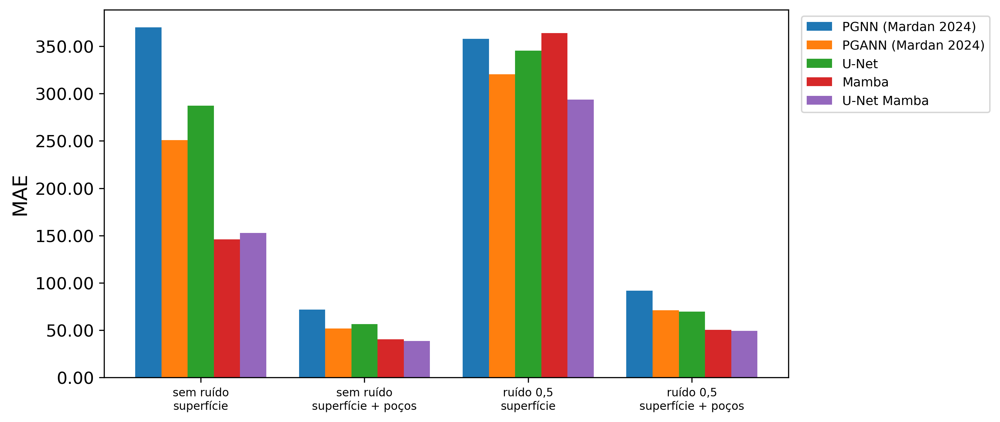

#### SSIM

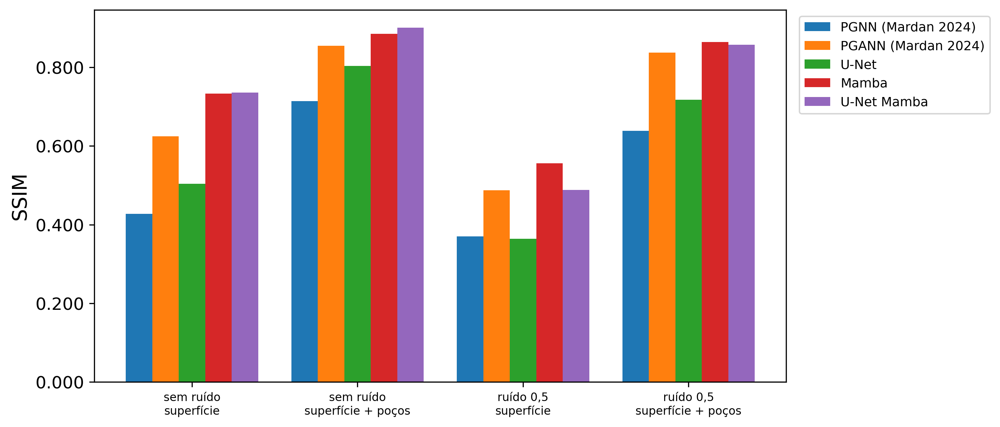

### CurveFault_B

Cenários de velocidade com falhas curvas.

#### MSE

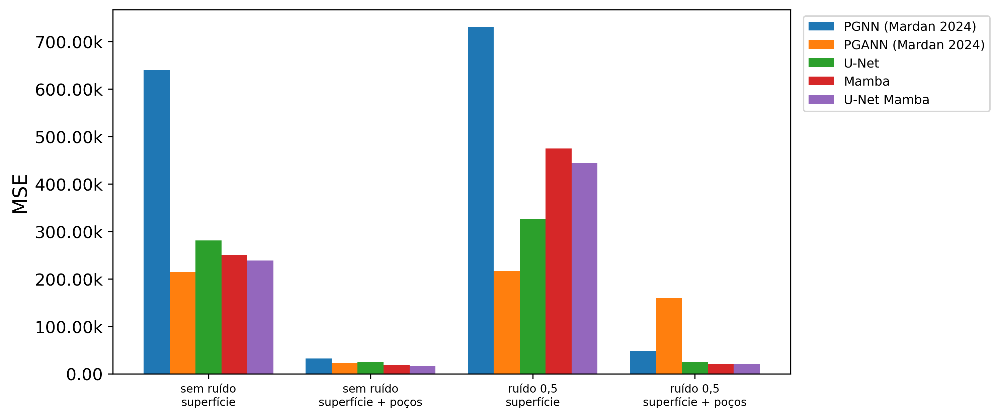

#### MAE

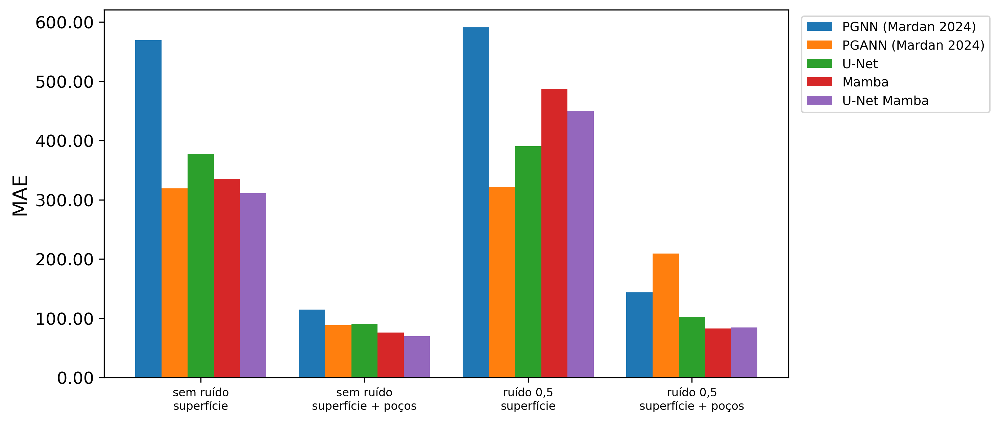

#### SSIM

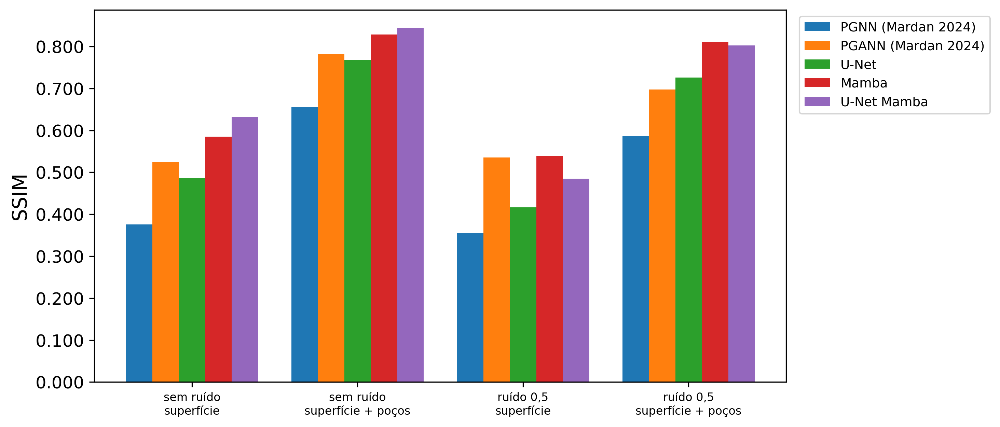

In [7]:
for dataset in PRESENTATION_CONFIG["datasets"]:
    dataset_name = dataset["name"]
    display(Markdown(f"### {dataset_name}\n\n{dataset['description']}"))
    figure_dir = scenario_output_dir(dataset_name) / "figures" / "metrics" / "by_scenario"
    for metric in PRESENTATION_CONFIG["metrics"]:
        figure_path = figure_dir / f"{dataset_name}_{metric['key']}_by_scenario.png"
        display(Markdown(f"#### {metric['label']}"))
        if figure_path.is_file():
            display(Image(filename=str(figure_path)))
        else:
            display(Markdown("Figura indisponível: não há valores válidos para esta métrica."))


## 7. Médias por ruído, geometria e modelo

As médias e figuras são calculadas separadamente para cada conjunto de dados. Dentro de uma seção, os cenários podem ser agrupados por ruído, geometria ou modelo; nenhum cálculo reúne conjuntos de dados diferentes.


## Marmousi

### Ruído

#### MSE

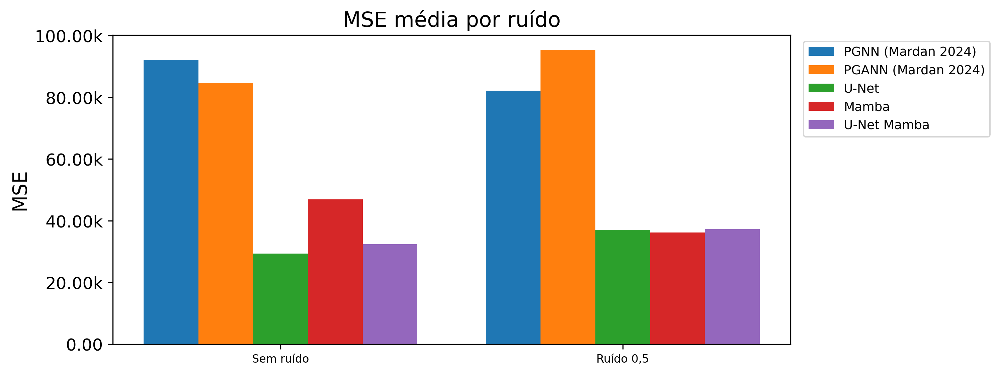

#### MAE

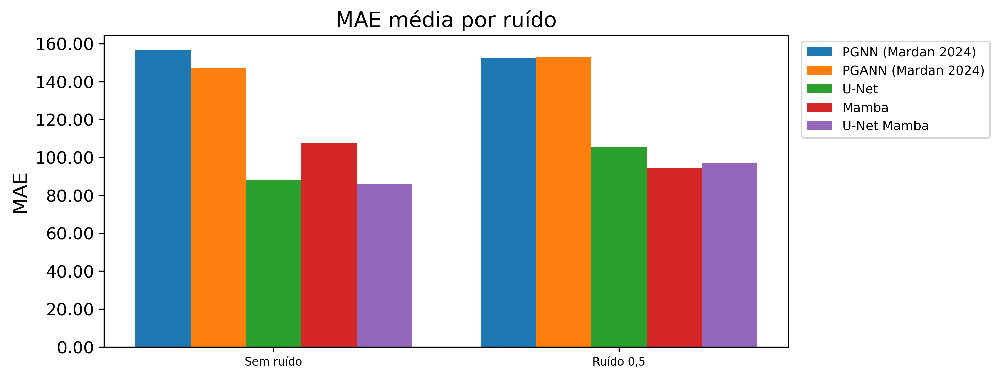

#### SSIM

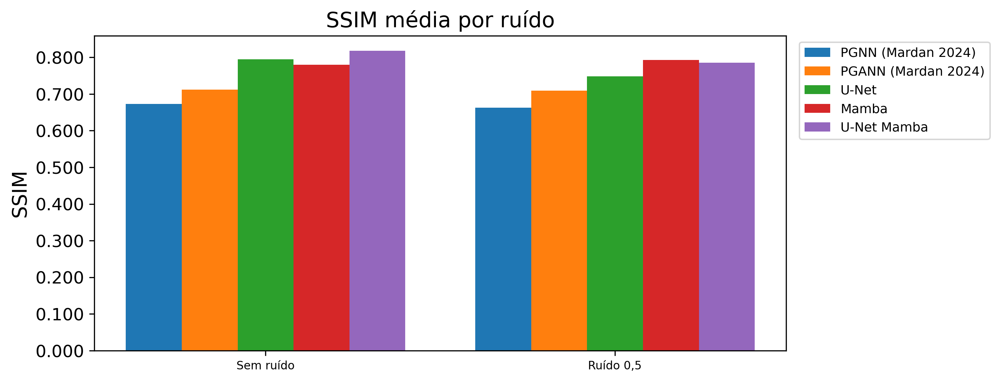

Tabela agrupada: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/Marmousi_model_scenarios/presentation_grouped_by_noise.csv


### Geometria

#### MSE

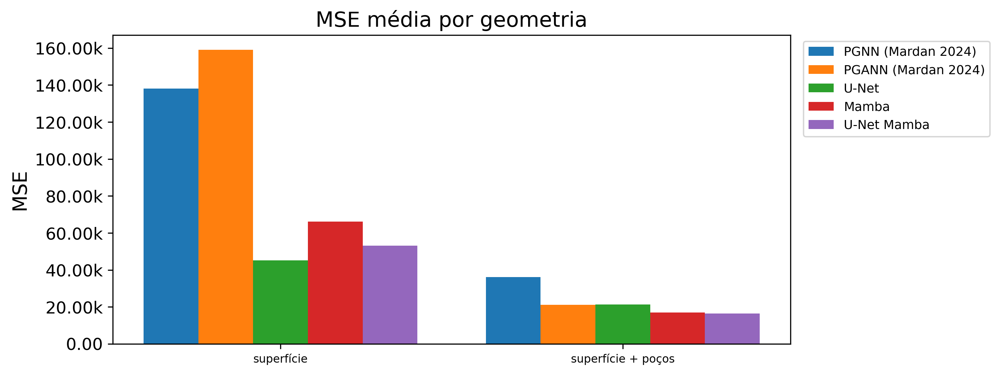

#### MAE

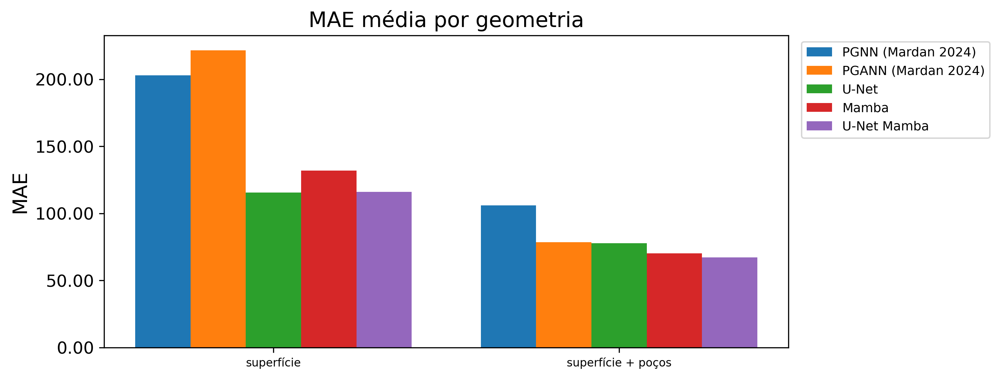

#### SSIM

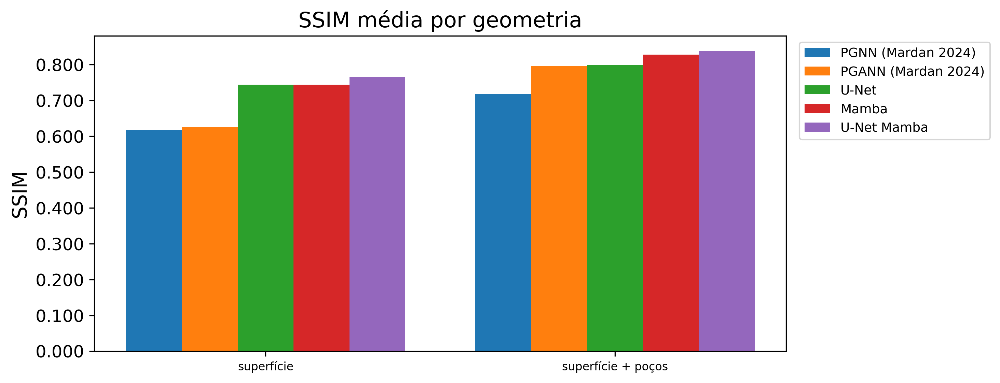

Tabela agrupada: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/Marmousi_model_scenarios/presentation_grouped_by_geometry.csv


### Modelo

#### MSE

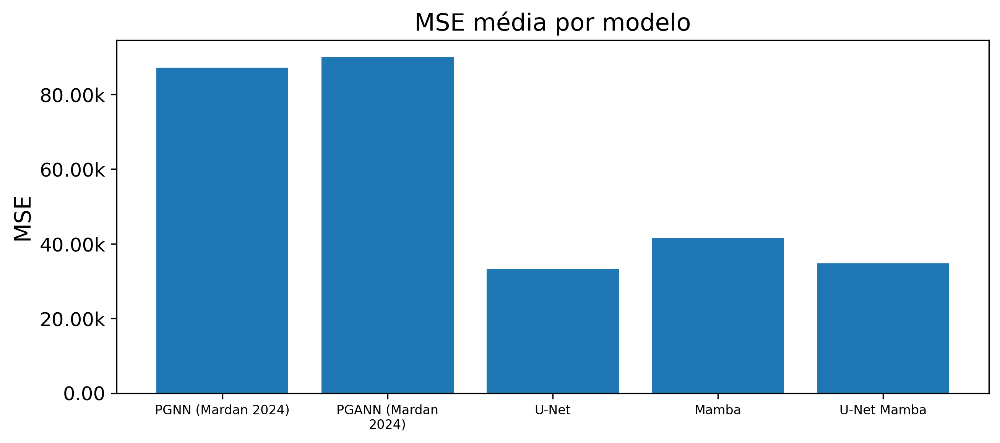

#### MAE

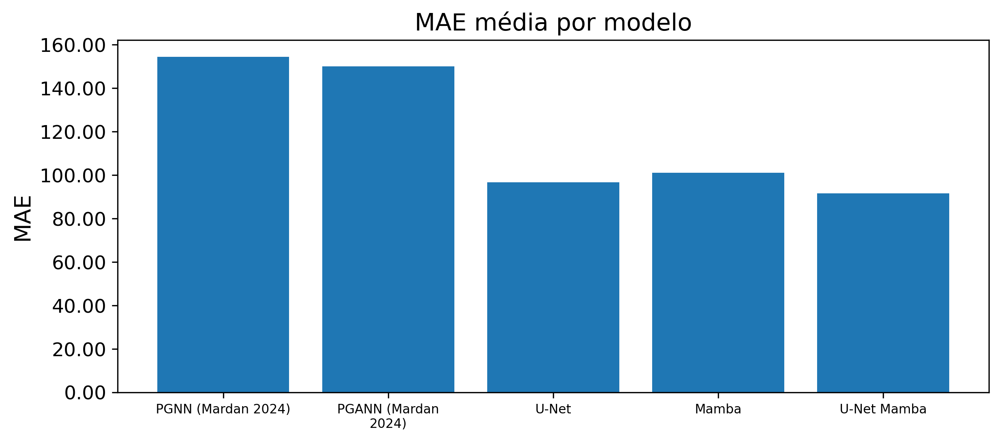

#### SSIM

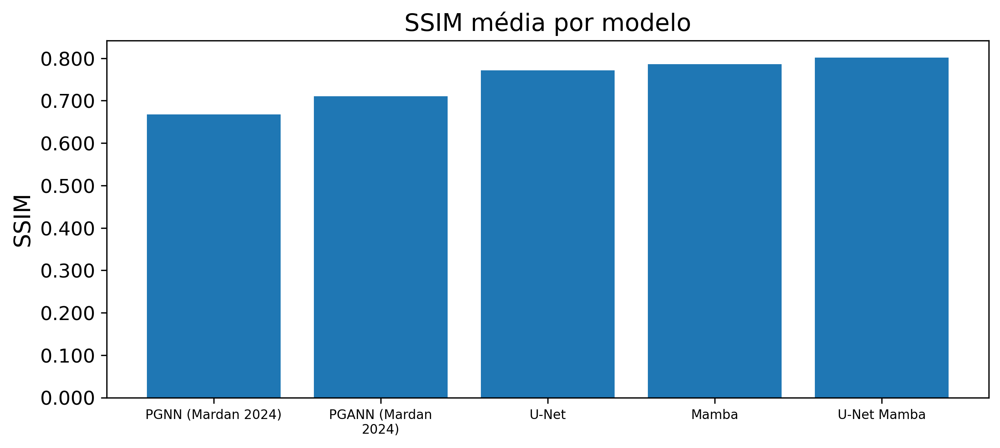

Tabela agrupada: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/Marmousi_model_scenarios/presentation_grouped_by_model.csv


## FlatFault_A

### Ruído

#### MSE

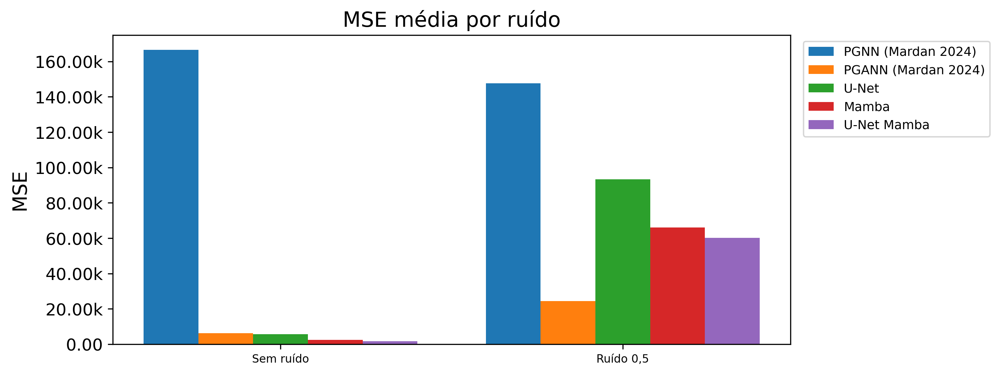

#### MAE

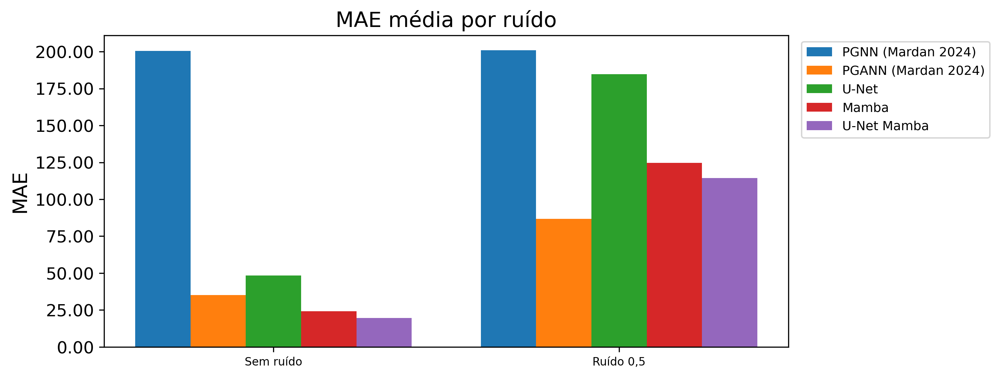

#### SSIM

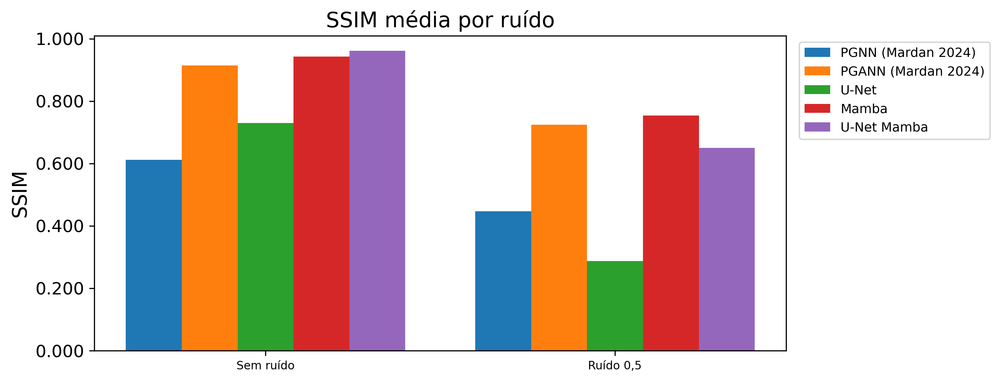

Tabela agrupada: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/FlatFault_A_model_scenarios/presentation_grouped_by_noise.csv


### Geometria

#### MSE

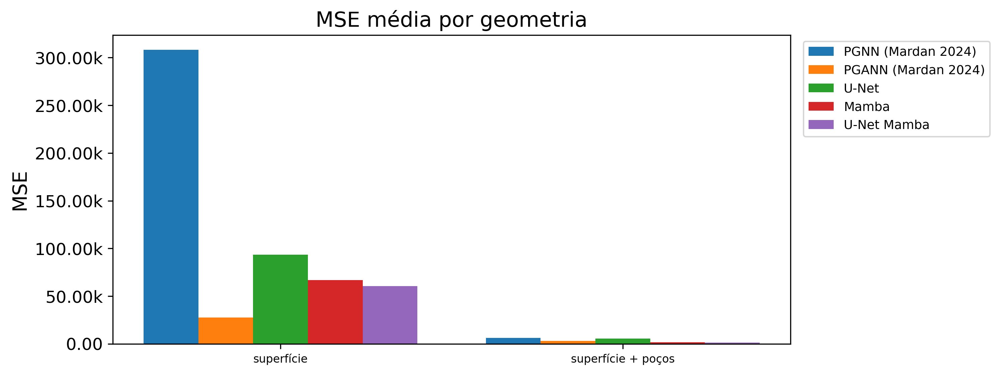

#### MAE

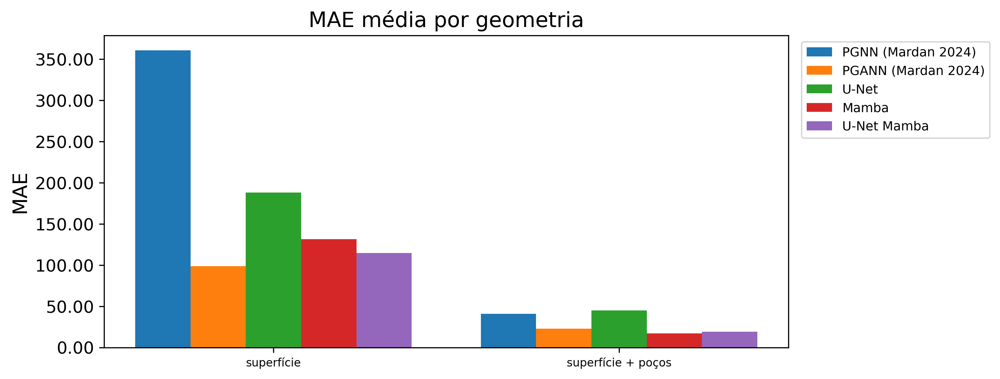

#### SSIM

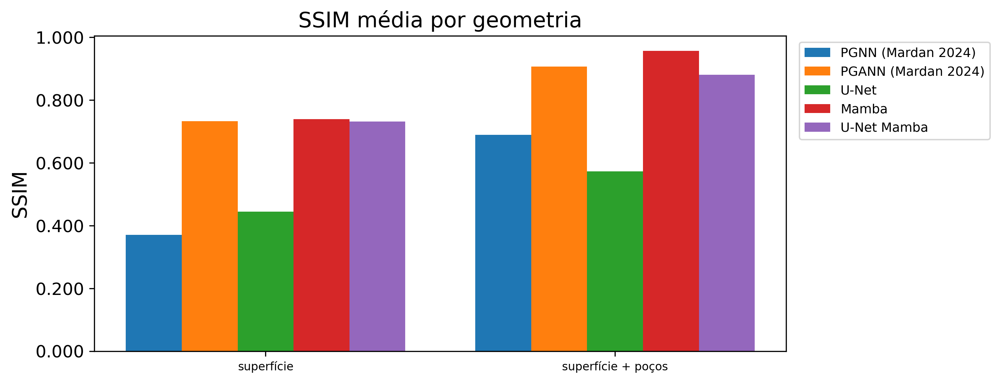

Tabela agrupada: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/FlatFault_A_model_scenarios/presentation_grouped_by_geometry.csv


### Modelo

#### MSE

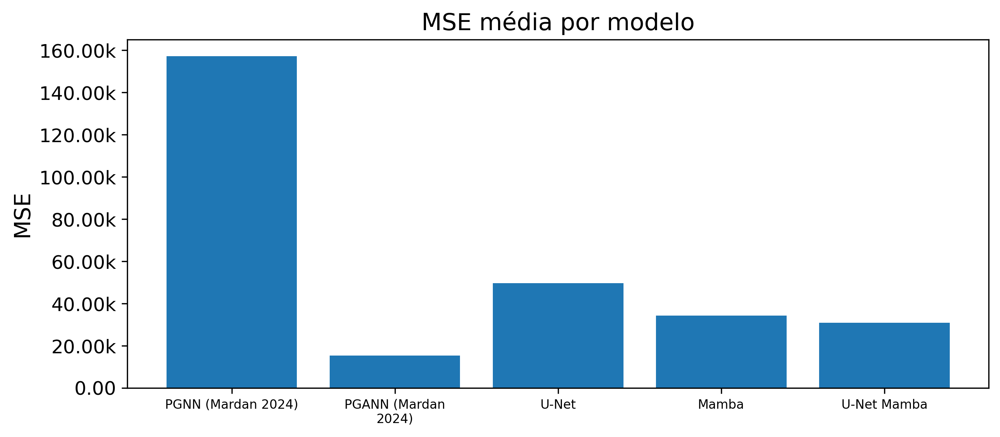

#### MAE

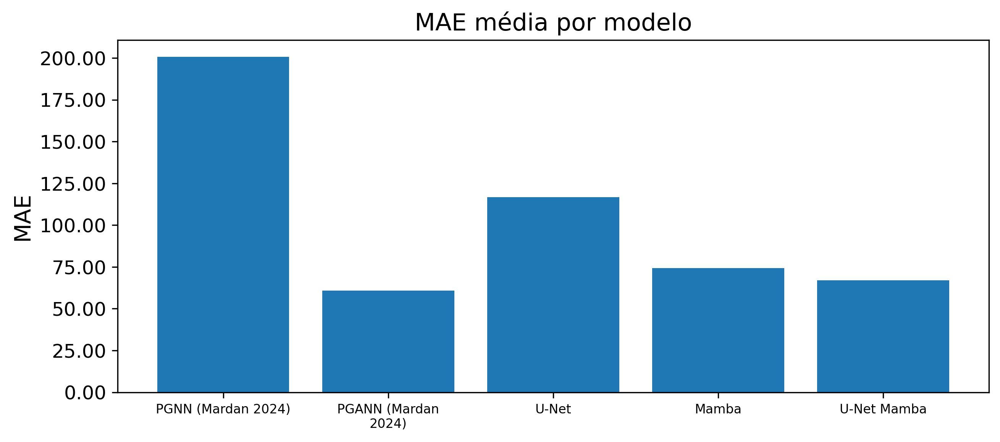

#### SSIM

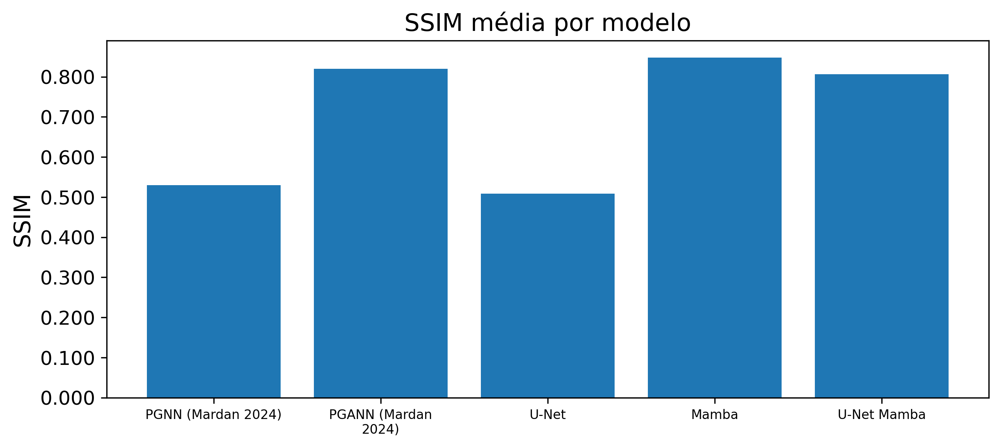

Tabela agrupada: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/FlatFault_A_model_scenarios/presentation_grouped_by_model.csv


## CurveVel_A

### Ruído

#### MSE

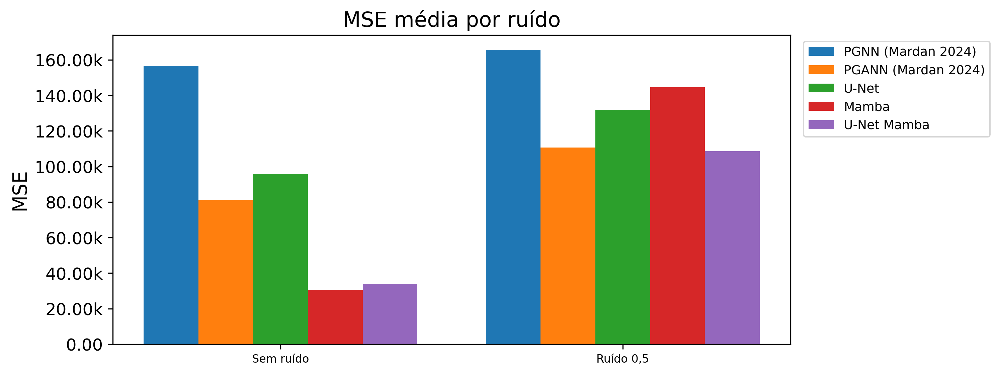

#### MAE

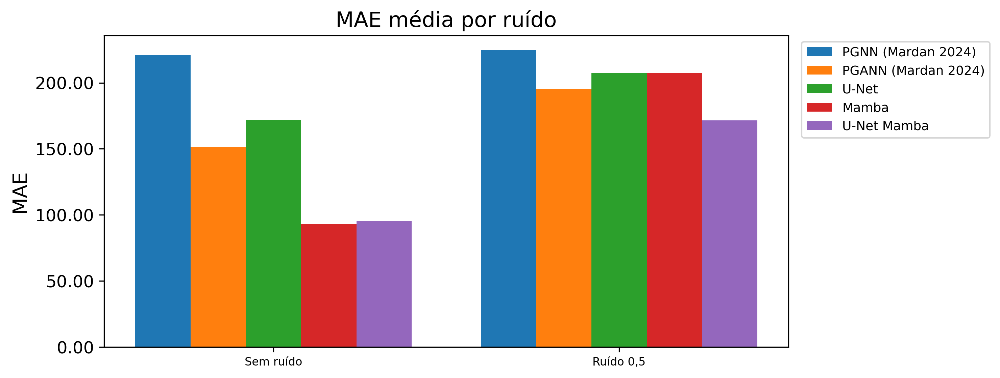

#### SSIM

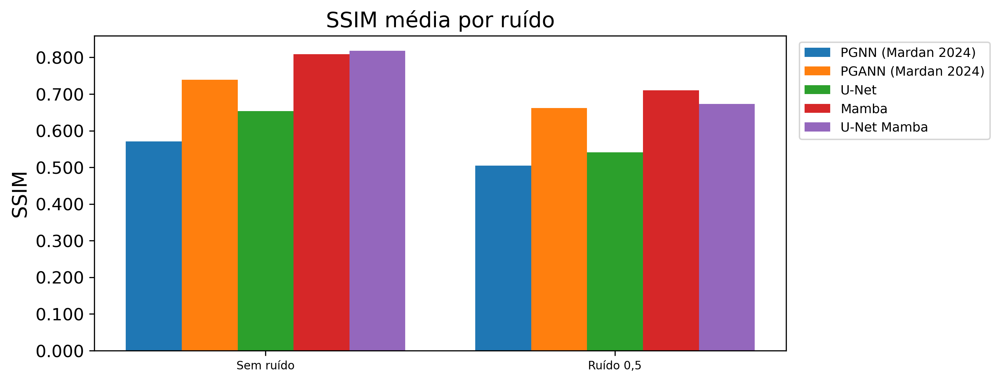

Tabela agrupada: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/CurveVel_A_model_scenarios/presentation_grouped_by_noise.csv


### Geometria

#### MSE

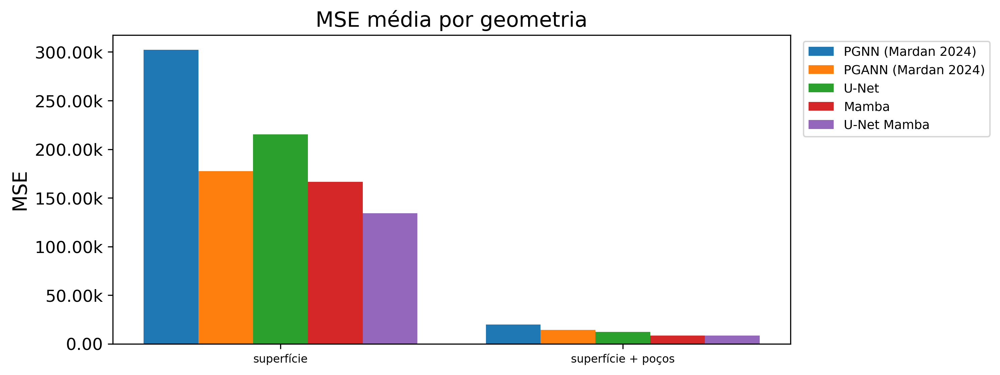

#### MAE

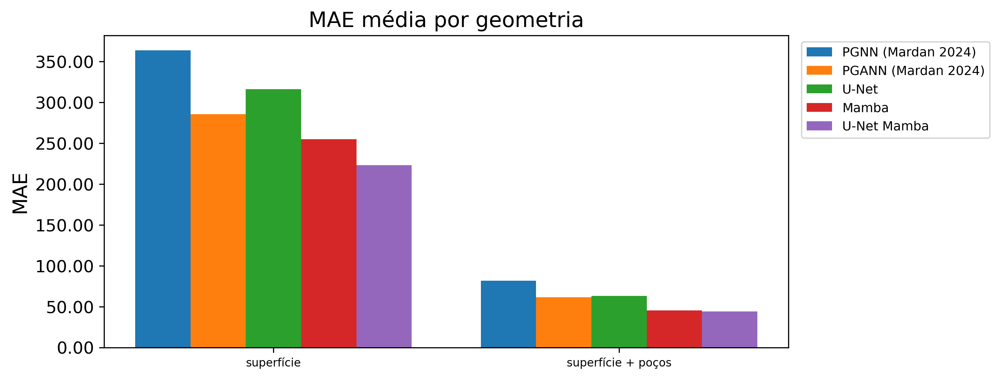

#### SSIM

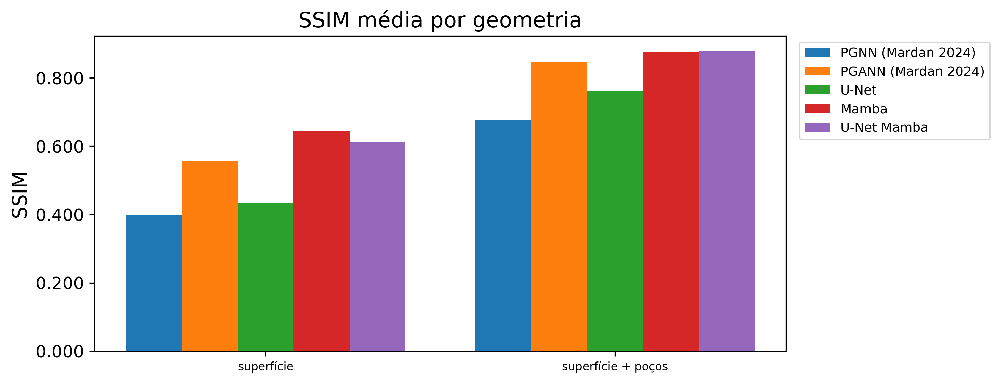

Tabela agrupada: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/CurveVel_A_model_scenarios/presentation_grouped_by_geometry.csv


### Modelo

#### MSE

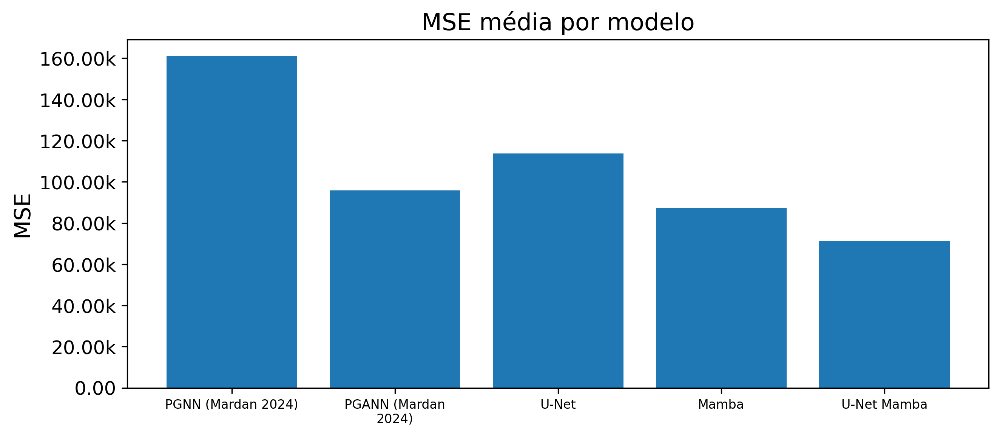

#### MAE

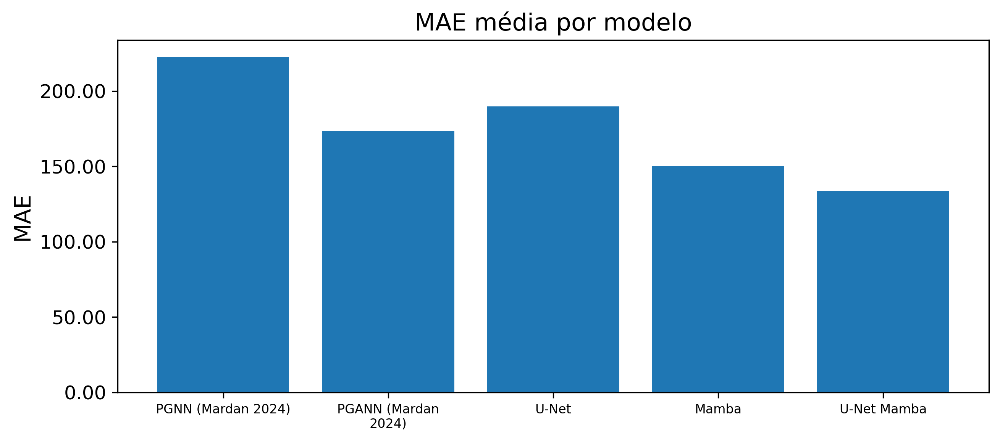

#### SSIM

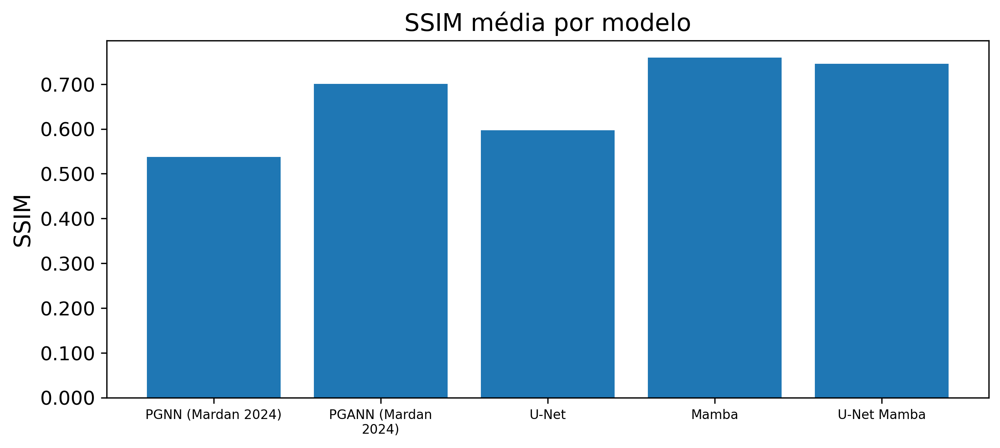

Tabela agrupada: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/CurveVel_A_model_scenarios/presentation_grouped_by_model.csv


## CurveFault_B

### Ruído

#### MSE

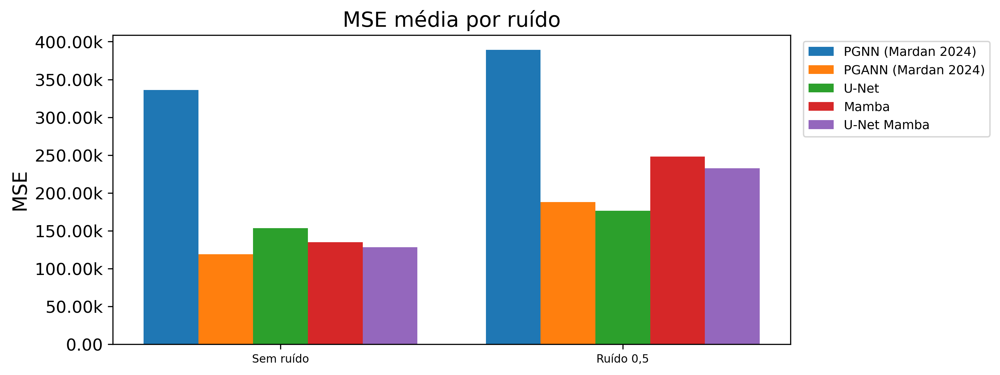

#### MAE

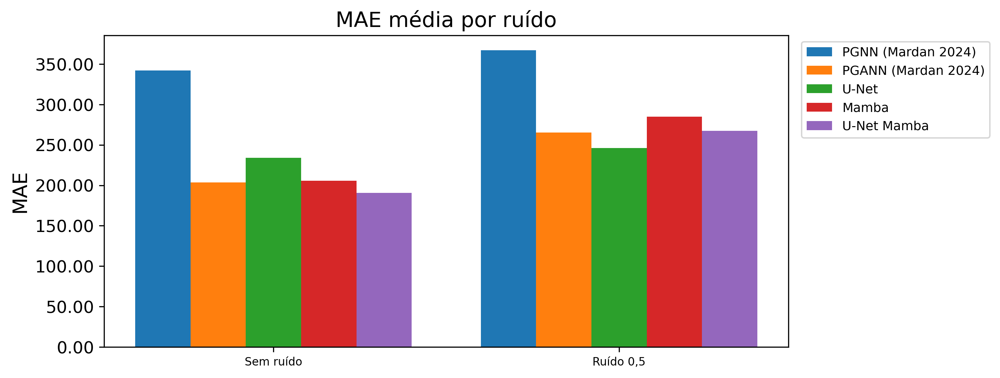

#### SSIM

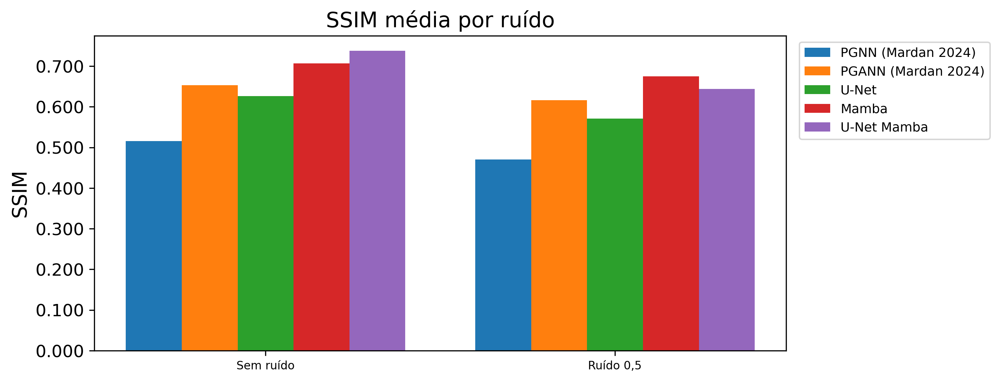

Tabela agrupada: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/CurveFault_B_model_scenarios/presentation_grouped_by_noise.csv


### Geometria

#### MSE

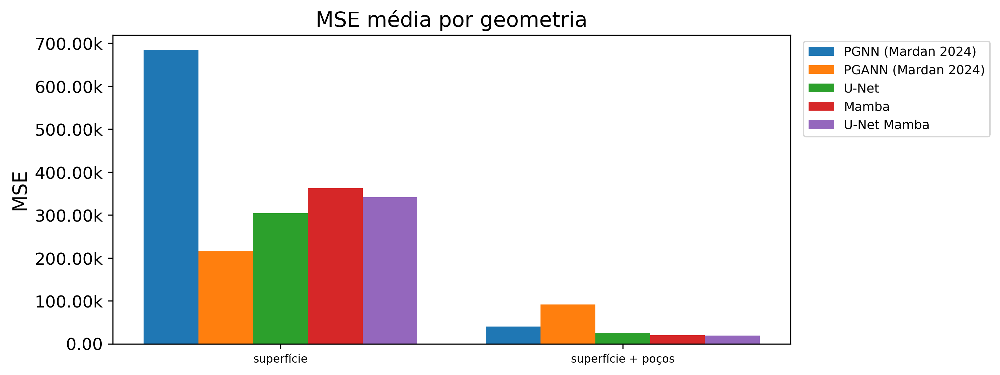

#### MAE

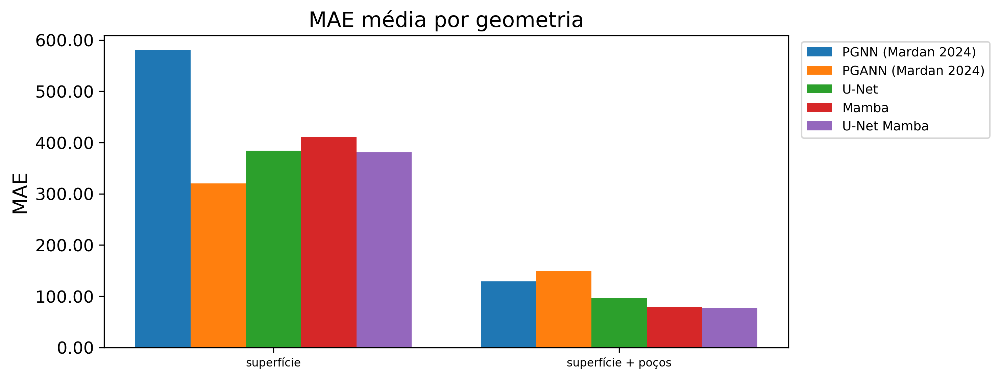

#### SSIM

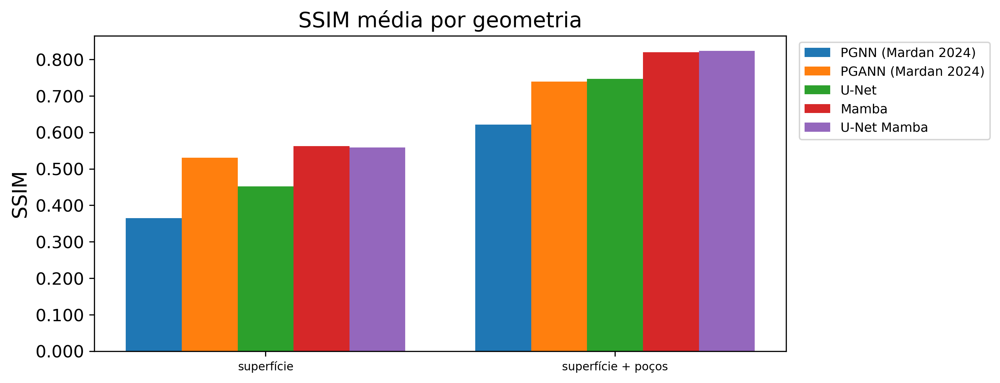

Tabela agrupada: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/CurveFault_B_model_scenarios/presentation_grouped_by_geometry.csv


### Modelo

#### MSE

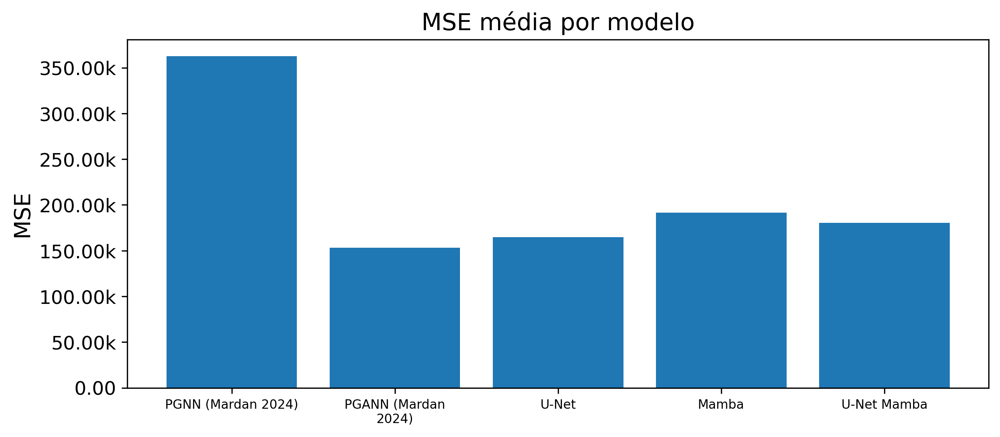

#### MAE

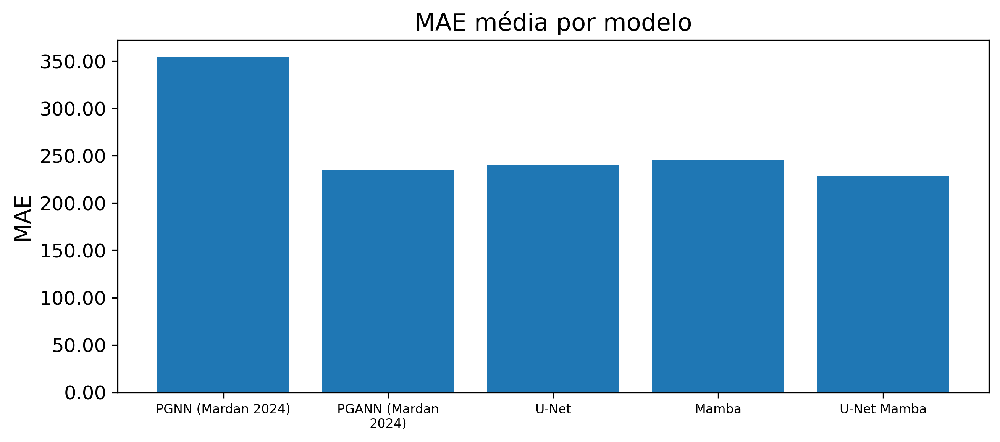

#### SSIM

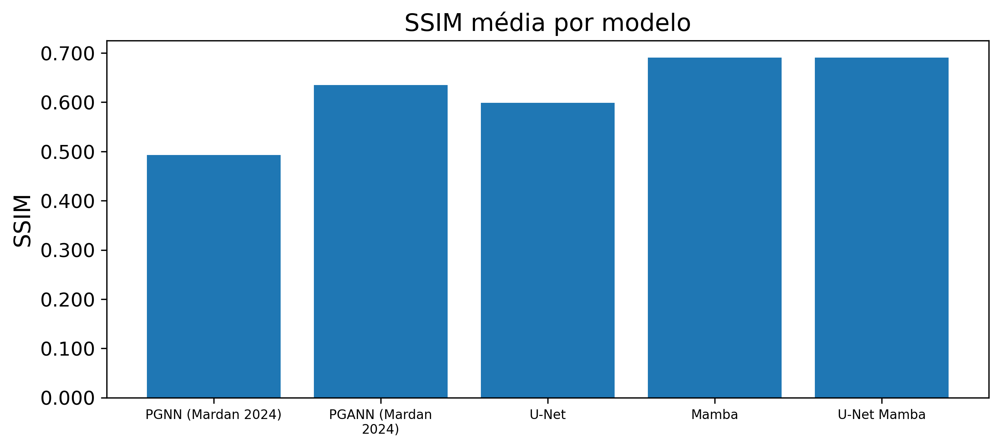

Tabela agrupada: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/CurveFault_B_model_scenarios/presentation_grouped_by_model.csv


In [8]:
grouped_metric_tables_by_dataset, grouped_metric_table_paths_by_dataset = write_scenario_grouped_presentation_tables(
    PRESENTATION_CONFIG,
)
GROUP_LABELS_PT_BR = {"noise": "Ruído", "geometry": "Geometria", "model": "Modelo"}
grouped_metric_figures_by_dataset = {}
for dataset_name in DATASET_NAMES:
    grouped_metric_figure_dir = scenario_output_dir(dataset_name) / "figures" / "metrics" / "grouped"
    grouped_metric_tables = grouped_metric_tables_by_dataset[dataset_name]
    grouped_metric_figures_by_dataset[dataset_name] = plot_grouped_scenario_metric_charts(
        grouped_metric_tables,
        metric_definitions=PRESENTATION_CONFIG["metrics"],
        output_dir=grouped_metric_figure_dir,
    )
    display(Markdown(f"## {dataset_name}"))
    for group_name in ("noise", "geometry", "model"):
        display(Markdown(f"### {GROUP_LABELS_PT_BR[group_name]}"))
        for metric in PRESENTATION_CONFIG["metrics"]:
            figure_path = grouped_metric_figure_dir / f"{group_name}_{metric['key']}_mean.png"
            display(Markdown(f"#### {metric['label']}"))
            if figure_path.is_file():
                display(Image(filename=str(figure_path)))
            else:
                display(Markdown("Figura indisponível: não há valores válidos para esta métrica."))
        print("Tabela agrupada:", grouped_metric_table_paths_by_dataset[dataset_name][group_name])


## 8. Desempenho por conjunto de dados

Latência e pico de memória são resumidos separadamente para cada conjunto de dados. Cada média agrega apenas as inferências válidas daquele conjunto de dados, reunindo seus níveis de ruído e épocas. As geometrias de receptor seguem em grupos separados.

O resumo usa os CSVs por amostra já salvos, sem repetir inferência. A memória GPU fica vazia quando não foi medida.

A memória é apresentada em MB decimais: os bytes alocados pelo PyTorch são divididos por 1.000.000.


Resumo salvo em: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/presentation_runtime_by_dataset.csv


## Marmousi

### Latência mediana de inferência (ms por amostra)

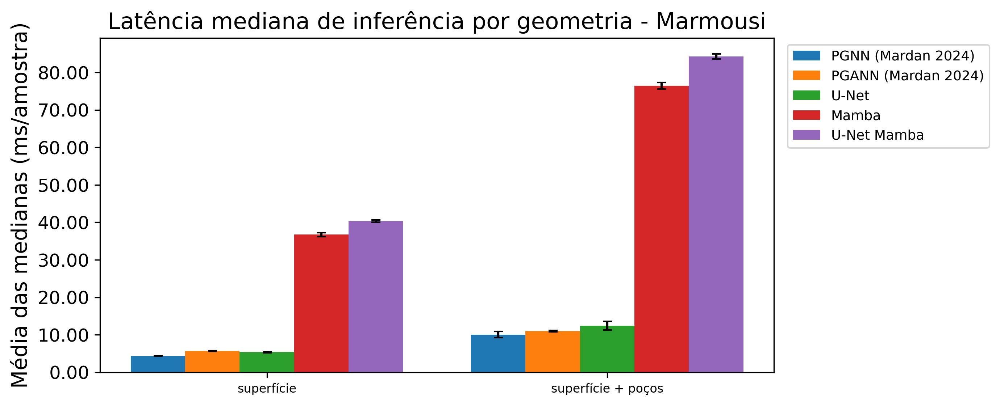

### Pico de memória GPU (MB)

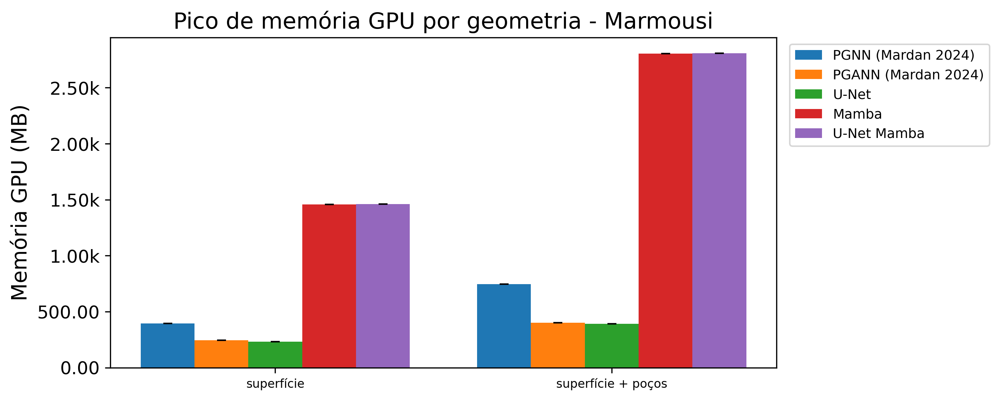

## FlatFault_A

### Latência mediana de inferência (ms por amostra)

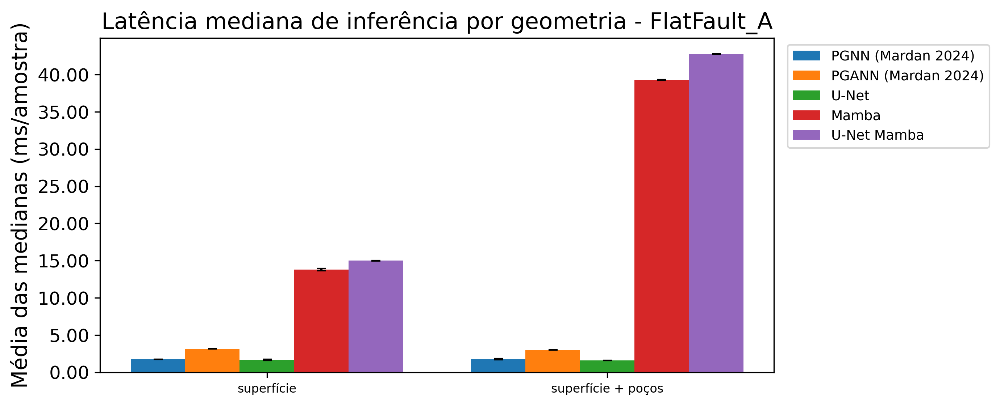

### Pico de memória GPU (MB)

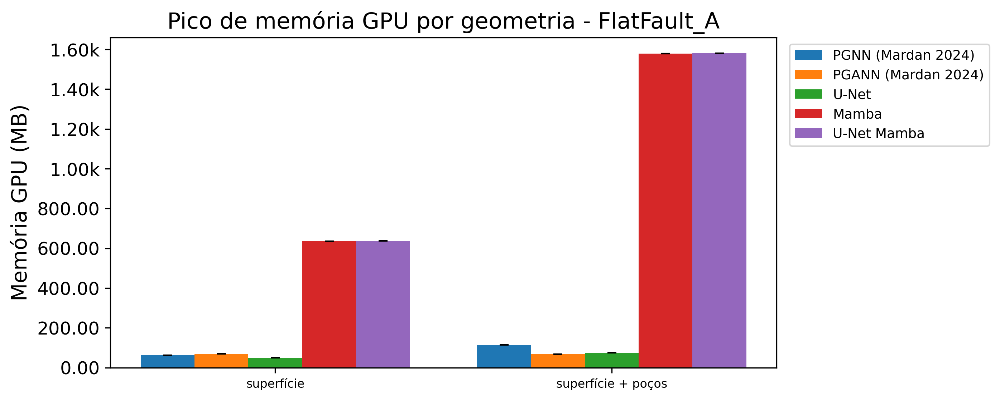

## CurveVel_A

### Latência mediana de inferência (ms por amostra)

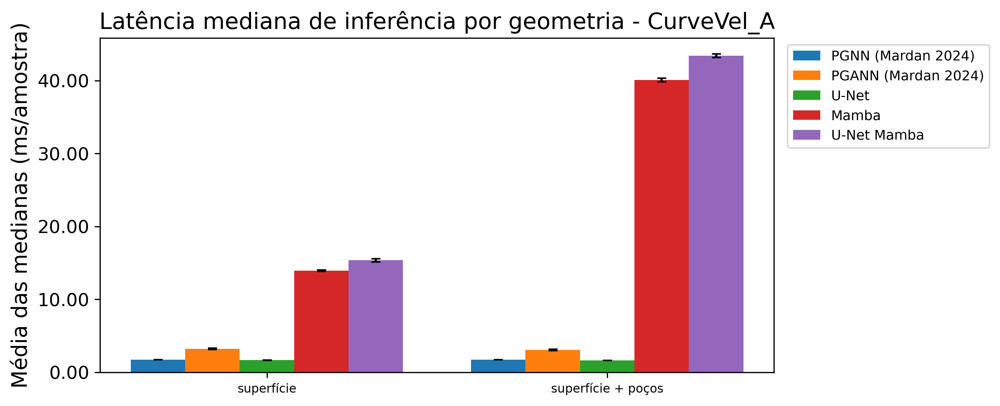

### Pico de memória GPU (MB)

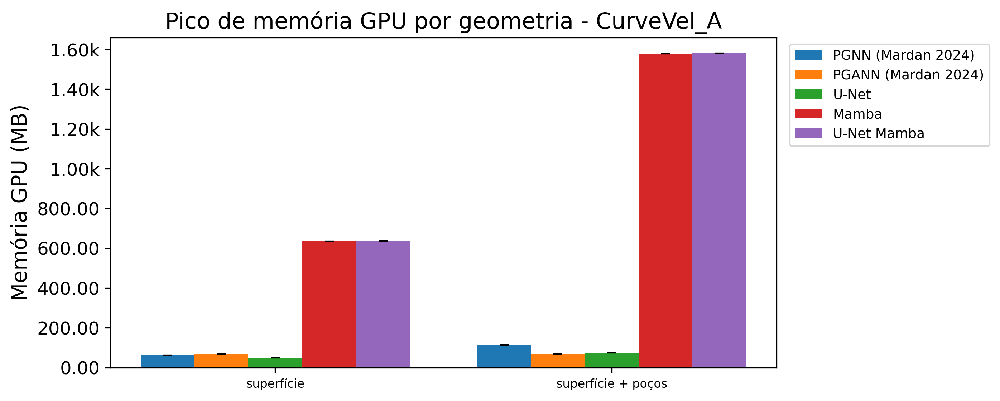

## CurveFault_B

### Latência mediana de inferência (ms por amostra)

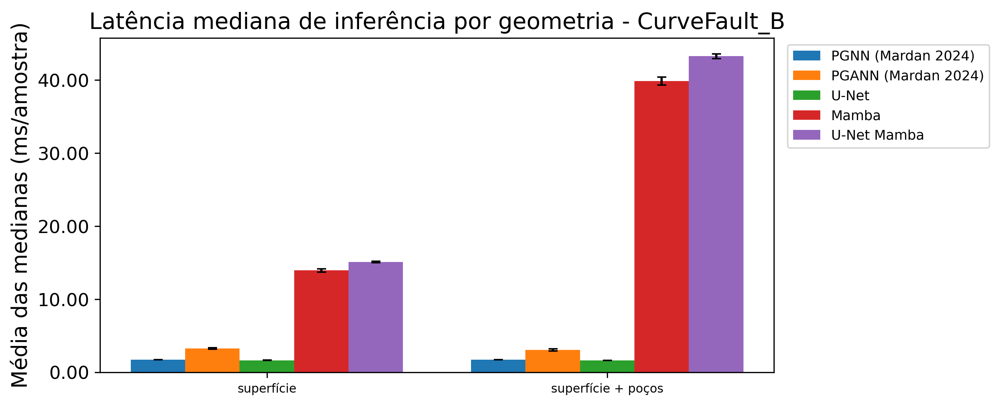

### Pico de memória GPU (MB)

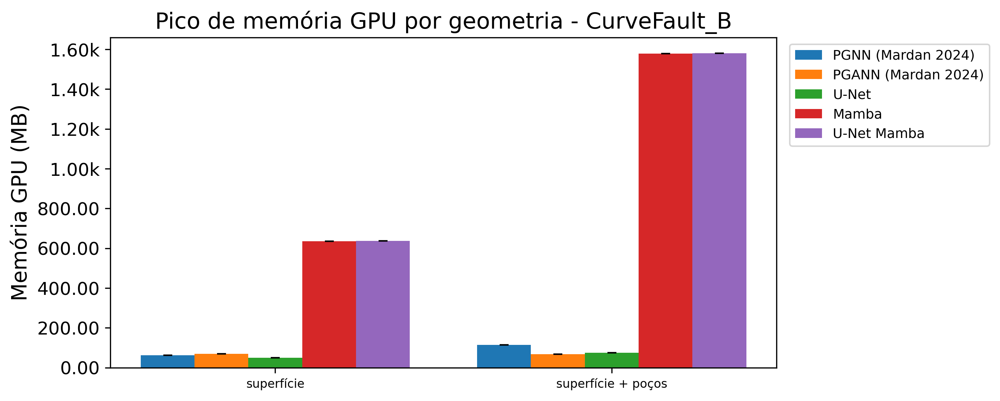

In [9]:
runtime_table, runtime_table_path = write_scenario_runtime_presentation_table(
    PRESENTATION_CONFIG,
)
runtime_figure_dir = EVALUATION_ROOT / PRESENTATION_CONFIG["version"] / "figures" / "runtime" / "by_dataset"
runtime_figures = plot_scenario_runtime_charts(
    runtime_table,
    performance_definitions=PRESENTATION_CONFIG["performance_metrics"],
    output_dir=runtime_figure_dir,
)
print("Resumo salvo em:", runtime_table_path)

for dataset in PRESENTATION_CONFIG["datasets"]:
    dataset_name = dataset["name"]
    slug = dataset_name.casefold().replace(" ", "_")
    display(Markdown(f"## {dataset_name}"))
    for metric in PRESENTATION_CONFIG["performance_metrics"]:
        figure_path = runtime_figure_dir / f"{slug}_{metric['key']}_by_geometry.png"
        display(Markdown(f"### {metric['label']} ({metric['unit']})"))
        if figure_path.is_file():
            display(Image(filename=str(figure_path)))
        elif metric["key"] == "peak_gpu_memory_mb":
            display(Markdown("Memória GPU indisponível: nenhuma inferência válida mediu o uso da GPU."))
        else:
            display(Markdown("Figura indisponível: não há medições de latência válidas."))


### 8.1. Comparação de memória dos modelos Mamba

A tabela compara os picos de memória CUDA com os blocos Mamba ativados e desativados para pares do mesmo conjunto de dados, cenário e amostra. O aumento percentual é calculado primeiro em cada par, como $(M_{ativo}/M_{inativo}-1)\times100$, e depois resumido pela média e pelo desvio padrão entre amostras. Assim, o percentual não é calculado pela razão entre as médias de memória. A variante desativada substitui os blocos Mamba do encoder, bottleneck e decoder por identidades e carrega os pesos convolucionais compartilhados do mesmo checkpoint. Não há retreinamento. A tabela agregada e os pares por amostra são salvos junto aos resultados da versão avaliada.


In [10]:
mamba_memory_output_path = (
    EVALUATION_ROOT
    / PRESENTATION_CONFIG["version"]
    / "mamba_memory_comparison.csv"
)
mamba_memory_table, mamba_memory_failures = benchmark_mamba_memory_variants(
    scenario_results,
    DATASET_NAMES,
    device=DEVICE,
    warmup_runs=PERFORMANCE_BENCHMARK.get("warmup_runs", 1),
    output_path=mamba_memory_output_path,
)
def _memory_mean_std(row, label):
    mean = row[f"Pico médio com Mamba {label} (MB)"]
    std = row[f"Desvio padrão com Mamba {label} (MB)"]
    return "N/A" if pd.isna(mean) else f"{mean:.1f} ± {std:.1f}"

def _percentage_mean_std(row):
    mean = row["Aumento percentual médio por amostra (%)"]
    std = row["Desvio padrão do aumento percentual por amostra (%)"]
    return "N/A" if pd.isna(mean) else f"{mean:.1f} ± {std:.1f}%".replace(".", ",")

mamba_memory_display_table = pd.DataFrame({
    ("Conjunto de dados", ""): mamba_memory_table["Conjunto de dados"],
    ("Modelo", ""): mamba_memory_table["Modelo"],
    ("Amostras pareadas", "n"): mamba_memory_table["Comparações pareadas (n)"],
    ("Mamba — pico médio ± desvio padrão (MB)", "Ativado"): mamba_memory_table.apply(
        lambda row: _memory_mean_std(row, "ativado"), axis=1
    ),
    ("Mamba — pico médio ± desvio padrão (MB)", "Desativado"): mamba_memory_table.apply(
        lambda row: _memory_mean_std(row, "desativado"), axis=1
    ),
    ("Aumento percentual por amostra (média ± dp)", ""): mamba_memory_table.apply(
        _percentage_mean_std, axis=1
    ),
})
mamba_memory_display_table.columns = pd.MultiIndex.from_tuples(
    mamba_memory_display_table.columns
)
display(mamba_memory_display_table.style.hide(axis="index").set_table_styles([
    {"selector": "th", "props": [("background-color", "#111827"), ("color", "white"), ("text-align", "center")]},
    {"selector": "td", "props": [("padding", "5px 8px"), ("text-align", "center")]},
]))
if not mamba_memory_failures.empty:
    display(Markdown("Falhas nas medições pareadas (até 10 exibidas):"))
    display(mamba_memory_failures.head(10))
print("Tabela agregada salva em:", mamba_memory_output_path)
print("Pares por amostra salvos em:", mamba_memory_output_path.with_name(
    f"{mamba_memory_output_path.stem}_samples{mamba_memory_output_path.suffix}"
))


Tabela agregada salva em: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/mamba_memory_comparison.csv
Pares por amostra salvos em: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/mamba_memory_comparison_samples.csv


## 9. Propagação das fontes: referência e U-Net Mamba

O GIF combina lado a lado a propagação pelo modelo de velocidade de referência e pela predição U-Net Mamba do cenário limpo com mais épocas disponível. Ambos usam a geometria e a física Marmousi da análise de dados.


Cenário U-Net Mamba: U-Net Mamba | sem ruído | 500 épocas | superfície + poços
GIF da predição: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/Marmousi_model_scenarios/figures/seismic_acquisition/Marmousi_s0000_unetmamba_wavefield.gif
Comparação lado a lado: /home/caiopinho/projects/tcc-fwi/results/evaluation/v8/Marmousi_model_scenarios/figures/seismic_acquisition/Marmousi_s0000_reference_vs_unetmamba.gif


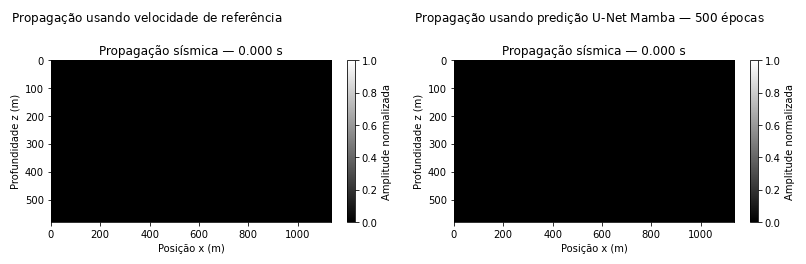

PosixPath('/home/caiopinho/projects/tcc-fwi/results/evaluation/v8/Marmousi_model_scenarios/figures/seismic_acquisition/Marmousi_s0000_reference_vs_unetmamba.gif')

In [11]:
display_unetmamba_wavefield_comparison(
    scenario_result=scenario_results["Marmousi"],
    dataset_name="Marmousi",
    sample_id=0,
    version=PRESENTATION_CONFIG["version"],
    checkpoint_root=DEFAULT_CHECKPOINT_ROOT,
    output_dir=scenario_output_dir("Marmousi"),
    preferred_geometry=DATASET_RECEIVER_GEOMETRIES["Marmousi"][-1],
    device=DEVICE,
    callback_frequency=10,
)